In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import CoolProp.CoolProp as CP
import thermo as thermo
import time as timer
import cProfile
import pstats
import yaml
import copy
import sys
from scipy.optimize import brentq
from thermal import *

In [2]:
class HeatingElement:
    """
    Cylindrical resistive heating element at the centre of the graphite annulus.

    Modelled as a gray-body radiator with uniform surface temperature.  Heat is
    transferred from the heater to the graphite inner wall via thermal radiation
    in a two-surface coaxial enclosure.  No thermal mass is assumed: the heater
    equilibrium temperature is solved algebraically each timestep from the
    electrical power supplied and the current graphite inner-wall temperature.

    Control phases
    --------------
    Phase 1 (power-limited):  supply max_power at the lowest heater temperature
        that drives that flux into the graphite.  T_heater rises as the graphite
        warms and the temperature difference shrinks.
    Phase 2 (temperature-limited):  once T_heater would exceed max_temperature,
        clamp T_heater = max_temperature and supply whatever heat that drives.
        Power delivered decreases as the block approaches max_temperature.

    The simulation stops when T_avg_block >= T_block_max.

    Attributes
    ----------
    diameter        : float -- heater rod outer diameter [m]
    max_temperature : float -- maximum allowed heater surface temperature [K]
    max_power       : float -- maximum electrical power input [W]
    emissivity      : float -- gray-body emissivity of the heater surface
    """

    def __init__(self, diameter, max_temperature, max_power, emissivity):
        """
        Inputs
        ------
        diameter        : float -- heater rod outer diameter [m]
        max_temperature : float -- maximum allowed heater surface temperature [K]
        max_power       : float -- maximum electrical power input [W]
        emissivity      : float -- gray-body emissivity of the heater surface
        """
        self.diameter        = float(diameter)
        self.max_temperature = float(max_temperature)
        self.max_power       = float(max_power)
        self.emissivity      = float(emissivity)

class TinlessSimulation:
    """
    Transient model: graphite annulus radiating to a central cylindrical powerstick.
    Each timestep reads inner wall temps, computes radiation + electricity, and updates
    the block temperature distribution via StorageModule.update_temps.
    """

    def __init__(self, storage, powerstick, T_sur=300, block_heat_loss=False,
                 shade_bool=False, shade_side_len=None, N_shades=2,
                 f_shade_min=0.0, f_shade_max=0.9, nominal_cell_flux=None):
        self.storage         = storage
        self.powerstick      = powerstick
        self.T_sur           = T_sur
        self.block_heat_loss = block_heat_loss

        r_ps_eff      = 2 * powerstick.width / np.pi
        r_in          = storage.block.rad_in
        self.VF       = r_ps_eff / r_in
        self.A_ps_seg = powerstick.A_step

        if powerstick.liner_bool:
            if powerstick.liner_width is None:
                raise ValueError("PowerStick.liner_width must be set when liner_bool=True")
            r_liner          = 2 * powerstick.liner_width / np.pi
            self.VF_gr_liner = r_liner / r_in
            self.VF_liner_ps = r_ps_eff / r_liner
            self.A_liner_seg = 2 * np.pi * r_liner * powerstick.height_step
        else:
            self.VF_gr_liner = None
            self.VF_liner_ps = None
            self.A_liner_seg = None

        self.shade_bool       = shade_bool
        self.N_shades         = N_shades
        self.f_shade_min      = f_shade_min
        self.f_shade_max      = f_shade_max
        self.nominal_cell_flux = nominal_cell_flux
        if shade_bool:
            if not powerstick.liner_bool:
                raise ValueError("shade_bool=True requires liner_bool=True")
            if shade_side_len is None:
                raise ValueError("shade_side_len must be set when shade_bool=True")
            r_shade           = 2 * shade_side_len / np.pi
            self.VF_gr_shade  = r_shade / r_in
            self.VF_shade_lin = r_liner / r_shade
            self.A_shade_seg  = 2 * np.pi * r_shade * powerstick.height_step
        else:
            self.VF_gr_shade  = None
            self.VF_shade_lin = None
            self.A_shade_seg  = None

    def spectral_net_radiation(self, T_hot, f_shade=0.0):
        """
        Incident radiative power [W] on the powerstick from a hot graphite surface.

        liner_bool=False: graphite inner wall -> powerstick directly.
                          Returns (Q_total, None).
        liner_bool=True:  graphite -> tungsten liner -> powerstick.
                          Returns (Q_ps, T_liner).
        """
        h   = 6.62607015e-34
        c   = 2.99792458e8
        k_B = 1.380649e-23

        emissivity_table = self.powerstick.emissivity_table
        liner_bool       = self.powerstick.liner_bool
        f_bare           = self.powerstick.f_bare
        f_active         = self.powerstick.f_active
        VF               = self.VF
        A_ps             = self.A_ps_seg
        shade_bool      = self.shade_bool
        VF_gr_liner      = self.VF_gr_liner
        VF_liner_ps      = self.VF_liner_ps
        A_liner_seg      = self.A_liner_seg
        VF_gr_shade     = self.VF_gr_shade
        VF_shade_lin    = self.VF_shade_lin
        A_shade_seg     = self.A_shade_seg

        wavelength_min = emissivity_table[0][0][0]
        wavelength_max = emissivity_table[-1][0][1]
        band_gap       = emissivity_table[0][0][1]
        n_bins = 300

        wavelengths   = np.logspace(np.log10(wavelength_min), np.log10(wavelength_max), n_bins)
        wavelengths_m = wavelengths * 1e-6

        def _B(T):
            return np.pi * (2*h*c**2) / wavelengths_m**5 / np.expm1(h*c / (wavelengths_m * k_B * T))

        bw_fwd = np.concatenate([wavelengths_m[1:] - wavelengths_m[:-1],
                                 [wavelengths_m[-1] - wavelengths_m[-2]]])
        bw_bwd = np.concatenate([[wavelengths_m[1] - wavelengths_m[0]],
                                 wavelengths_m[1:] - wavelengths_m[:-1]])
        bw = np.where(wavelengths < band_gap, bw_fwd, bw_bwd)

        avg_ps_emis = np.zeros(n_bins)
        for (wl_range, emis_active, emis_bare, emis_inactive) in emissivity_table:
            mask = (wavelengths >= wl_range[0]) & (wavelengths < wl_range[1])
            ep = (f_bare * emis_bare
                  + (1 - f_bare) * f_active       * emis_active
                  + (1 - f_bare) * (1 - f_active) * emis_inactive)
            avg_ps_emis[mask] = ep

        if not liner_bool:
            eps_gr = gr_emis(T_hot)
            B_hot  = _B(T_hot)
            denom  = VF * (1 - eps_gr) / eps_gr + 1 + (1 - avg_ps_emis) / avg_ps_emis
            return float(np.sum(B_hot * bw / denom)) * A_ps, None

        # ── Liner model: graphite -> tungsten liner -> powerstick ──────────
        sigma  = 5.67036713e-8
        eps_gr = gr_emis(T_hot)
        B_hot  = _B(T_hot)

        _shade_active = shade_bool and f_shade > 0 and A_shade_seg is not None
        _f_direct      = 1.0 - f_shade if _shade_active else 1.0
        if _shade_active:
            #eps_w       = w_emis_total(T_hot)
            eps_w       = wc_emis_grey(T_hot)
            A_shade_sh = f_shade * A_shade_seg
            A_liner_sh  = f_shade * A_liner_seg
            R1 = (VF_gr_shade  * (1 - eps_gr) / eps_gr + 1 + (1 - eps_w) / eps_w) / A_shade_sh
            R2 = (2 / eps_w - 1) / A_shade_sh
            R3 = (VF_shade_lin * (1 - eps_w)  / eps_w  + 1 + (1 - eps_w) / eps_w) / A_liner_sh
            R_shade = R1 + (self.N_shades - 1) * R2 + R3

        def _eps_liner(_T):
            return 0.55, 0.8

        def _balance(T_liner):
            eps_L_in, eps_L_out = _eps_liner(T_liner)
            B_lin     = _B(T_liner)
            denom_in  = VF_gr_liner * (1 - eps_gr) / eps_gr + 1 + (1 - eps_L_out) / eps_L_out
            Q_in      = _f_direct * float(np.sum((B_hot - B_lin) * bw / denom_in)) * A_liner_seg
            if _shade_active:
                Q_in += sigma * (T_hot**4 - T_liner**4) / R_shade
            denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
            Q_out     = float(np.sum(B_lin * bw / denom_out)) * A_ps
            return Q_in - Q_out

        T_liner = brentq(_balance, 400.0, T_hot - 1.0, xtol=1.0, maxiter=50)

        eps_L_in, _ = _eps_liner(T_liner)
        B_lin     = _B(T_liner)
        denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
        Q_ps      = float(np.sum(B_lin * bw / denom_out)) * A_ps
        return Q_ps, T_liner

    def _step_calc(self, T_dist, f_shade=0.0):
        ps   = self.powerstick
        n_ax = self.storage.num_ax_segments
        Q_rad   = np.zeros(n_ax)
        Q_elec  = np.zeros(n_ax)
        Q_cell  = np.zeros(n_ax)
        Q_waste = np.zeros(n_ax)
        T_liner = np.zeros(n_ax)
        for i in range(n_ax):
            T_wall_i = T_dist[i, 0]
            Q_rad[i], T_liner_i = self.spectral_net_radiation(T_wall_i, f_shade=f_shade)
            T_liner[i]  = T_liner_i if ps.liner_bool else 0.0
            T_emit_i = T_liner_i if ps.liner_bool else T_wall_i
            VF_emit  = self.VF_liner_ps if ps.liner_bool else self.VF
            Q_elec[i], Q_waste[i], Q_cell[i] = ps.generate_electricity_step(
                T_emit_i, VF_emit
            )
        return Q_rad, Q_elec, Q_cell, Q_waste, T_liner

    def _compute_f_shade(self, T_dist):
        """
        Bisect f_shade in [f_shade_min, f_shade_max] to match nominal_cell_flux
        [W/cm²].  Returns the nearest bound if the target lies outside the
        achievable range.
        """
        ps = self.powerstick
        A_cell_cm2 = 4 * ps.width * ps.height * (1 - ps.f_bare) * ps.f_active * 1e4

        def _flux(fs):
            _, _, Q_cell, _, _ = self._step_calc(T_dist, f_shade=fs)
            return Q_cell.sum() / A_cell_cm2

        f_lo, f_hi = self.f_shade_min, self.f_shade_max
        flux_lo = _flux(f_lo)
        flux_hi = _flux(f_hi)

        if flux_lo <= self.nominal_cell_flux:
            return f_lo   # min shade already below nominal; open to minimum
        if flux_hi >= self.nominal_cell_flux:
            return f_hi   # max shade still above nominal; clamp to max
        return brentq(lambda fs: _flux(fs) - self.nominal_cell_flux,
                      f_lo, f_hi, xtol=1e-4, maxiter=30)

    def run_simulation(self, end_time, dt_short, dt_medium, dt_long, sub_steps,
                       dt_short_duration=3600, snap_every=None, print_interval=0):
        storage = self.storage
        _use_shade = self.shade_bool and self.nominal_cell_flux is not None

        # ── Initial state ─────────────────────────────────────────────────────
        T = storage.block.temp_dist
        f_shade = self._compute_f_shade(T) if _use_shade else 0.0
        Q0, Q_elec0, Q_cell0, _, T_liner0 = self._step_calc(T, f_shade=f_shade)

        time_arr     = [0.0]
        Q_arr        = [Q0.sum()]
        Q_cell_arr   = [Q_cell0.sum()]
        Q_elec_arr   = [Q_elec0.sum()]
        T_avg_arr    = [T.mean()]
        T_inner_arr  = [T[:, 0].mean()]
        T_outer_arr  = [T[:, -1].mean()]
        T_liner_arr  = [T_liner0.mean()]
        f_shade_arr = [f_shade]
        snap_times   = [0.0]
        temp_snaps   = [T.copy()]

        t            = 0.0
        next_snap    = snap_every if snap_every else float('inf')
        last_print_t = -float('inf')

        # ── Time loop ─────────────────────────────────────────────────────────
        while t < end_time:
            T        = storage.block.temp_dist
            f_shade = self._compute_f_shade(T) if _use_shade else 0.0

            # Adaptive timestep
            if t < dt_short_duration or (self.shade_bool and f_shade == self.f_shade_max):
                dt = dt_short
            elif self.shade_bool and f_shade > self.f_shade_min:
                dt = dt_medium
            else:
                dt = dt_long
            dt = min(dt, end_time - t)

            Q_rad, Q_elec, Q_cell, Q_waste, T_liner = self._step_calc(T, f_shade=f_shade)
            T_new, _, _ = storage.update_temps(
                T, -Q_rad, dt, sub_steps, self.T_sur, self.block_heat_loss
            )
            storage.block.temp_dist = T_new
            t += dt

            time_arr.append(t)
            Q_arr.append(Q_rad.sum())
            Q_cell_arr.append(Q_cell.sum())
            Q_elec_arr.append(Q_elec.sum())
            T_avg_arr.append(T_new.mean())
            T_inner_arr.append(T_new[:, 0].mean())
            T_outer_arr.append(T_new[:, -1].mean())
            T_liner_arr.append(T_liner.mean())
            f_shade_arr.append(f_shade)

            if snap_every and t >= next_snap:
                snap_times.append(t)
                temp_snaps.append(T_new.copy())
                next_snap += snap_every

            if print_interval and (t - last_print_t >= print_interval):
                print(f"t = {t/3600:.2f} hr  "
                      f"T_avg = {T_new.mean():.0f} K  "
                      f"T_inner = {T_new[:,0].mean():.0f} K  "
                      f"T_liner = {T_liner.mean():.0f} K  "
                      f"Q = {Q_rad.sum()/1e3:.1f} kW  "
                      f"Q_cell = {Q_cell.sum()/1e3:.1f} kW  "
                      f"P_elec = {Q_elec.sum()/1e3:.1f} kW  "
                      f"f_sh = {f_shade:.3f}  dt = {dt:.0f} s")
                last_print_t = t

        if snap_times[-1] != t:
            snap_times.append(t)
            temp_snaps.append(storage.block.temp_dist.copy())

        return {
            'time':           np.array(time_arr),
            'Q_rad':          np.array(Q_arr),
            'Q_cell':         np.array(Q_cell_arr),
            'P_elec':         np.array(Q_elec_arr),
            'T_avg':          np.array(T_avg_arr),
            'T_inner':        np.array(T_inner_arr),
            'T_outer':        np.array(T_outer_arr),
            'T_liner':        np.array(T_liner_arr),
            'f_shade':       np.array(f_shade_arr),
            'snap_times':     np.array(snap_times),
            'temp_snapshots': np.array(temp_snaps),
        }

    def run_heating_simulation(self, heater, T_block_max, end_time, dt, sub_steps,
                                snap_every=None, print_interval=0):
        """
        Run a transient charging simulation with a central resistive heating element.

        The heater radiates outward to the graphite inner wall (opposite direction to
        discharge).  At each timestep the heater temperature is solved from a two-surface
        coaxial radiation enclosure model; the resulting per-segment heat flux is passed
        to StorageModule.update_temps as a positive source at j=0 (inner wall).

        The simulation runs until T_avg_block >= T_block_max or a hard cap of 1000
        timesteps is reached.

        Inputs
        ------
        heater      : HeatingElement -- heater object (diameter, max_temperature,
                                        max_power, emissivity)
        T_block_max : float          -- target charged block temperature [K];
                                        heating stops when T_avg >= T_block_max
        dt          : float          -- timestep [s]
        sub_steps   : int            -- finite-difference sub-steps per dt
        snap_every  : float|None     -- interval between full-field temperature
                                        snapshots [s]; None records start/end only
        print_interval : int         -- print status every N timesteps; 0 = silent

        Returns
        -------
        dict with keys:
          'time'           : ndarray -- time [s]
          'Q_heater'       : ndarray -- total heater power delivered [W]
          'T_heater'       : ndarray -- heater surface temperature [K]
          'T_avg'          : ndarray -- volume-average block temperature [K]
          'T_inner'        : ndarray -- axial-average inner wall temperature [K]
          'T_outer'        : ndarray -- axial-average outer wall temperature [K]
          'snap_times'     : ndarray -- times of full-field snapshots [s]
          'temp_snapshots' : ndarray -- (n_ax, n_rad) temperature field at each snap
        """

        sigma   = 5.67036713e-8
        storage = self.storage
        r_in    = storage.block.rad_in
        L_blk   = storage.block.length
        n_ax    = storage.num_ax_segments
        seg_len = L_blk / n_ax

        A_h_seg  = np.pi * heater.diameter * seg_len          # heater area / segment
        A_gr_seg = np.pi * 2.0 * r_in * seg_len               # graphite inner-wall area / seg
        eps_h    = heater.emissivity

        def _q_segs(T_h, T_inner_arr):
            """Per-segment radiation [W] from heater at T_h to graphite inner wall."""
            Q_seg = np.zeros(n_ax)
            for i in range(n_ax):
                eps_gr  = gr_emis(T_inner_arr[i])
                R_enc   = (1.0 - eps_h) / eps_h + 1.0 + (A_h_seg / A_gr_seg) * (1.0 - eps_gr) / eps_gr
                Q_seg[i] = sigma * (T_h**4 - T_inner_arr[i]**4) * A_h_seg / R_enc
            return Q_seg

        def _total_q(T_h, T_inner_arr):
            return float(_q_segs(T_h, T_inner_arr).sum())

        def _solve_T_heater(T_inner_arr):
            """Return (T_h, Q_segs) for the current timestep."""
            T_inner_max   = float(T_inner_arr.max())
            if T_inner_max >= heater.max_temperature:
                return T_inner_max, np.zeros(n_ax)
            q_at_max_temp = _total_q(heater.max_temperature, T_inner_arr)

            if q_at_max_temp >= heater.max_power:
                # Phase 1: find T_h < max_temperature that delivers max_power
                T_lo = T_inner_max + 0.1
                T_hi = heater.max_temperature
                try:
                    T_h = brentq(
                        lambda Th: _total_q(Th, T_inner_arr) - heater.max_power,
                        T_lo, T_hi, xtol=1.0, maxiter=50
                    )
                except ValueError:
                    T_h = heater.max_temperature
            else:
                # Phase 2: heater clamped at max_temperature, power falls below max
                T_h = heater.max_temperature

            return T_h, _q_segs(T_h, T_inner_arr)

        # ── Liner temperature helper (monitoring only) ───────────────────────
        ps_heat   = self.powerstick
        n_ax_heat = storage.num_ax_segments

        def _liner_avg(T_d):
            if not ps_heat.liner_bool:
                return 0.0
            tl = np.zeros(n_ax_heat)
            for i in range(n_ax_heat):
                _, tli = self.spectral_net_radiation(float(T_d[i, 0]))
                tl[i] = tli
            return float(tl.mean())

        # ── Initial state ────────────────────────────────────────────────────
        T         = storage.block.temp_dist.copy()
        T_h_0, _  = _solve_T_heater(T[:, 0])

        n_steps       = int(end_time / dt)
        snap_steps    = max(1, round(snap_every / dt)) if snap_every else n_steps
        time_list     = [0.0]
        Q_list        = [0.0]
        T_h_list      = [T_h_0]
        T_avg_list    = [float(T.mean())]
        T_inner_list  = [float(T[:, 0].mean())]
        T_outer_list  = [float(T[:, -1].mean())]
        T_liner_list  = [_liner_avg(T)]
        snap_times    = [0.0]
        temp_snaps    = [T.copy()]

        # ── Time-stepping ────────────────────────────────────────────────────
        for step in range(n_steps):
            T_inner_arr = T[:, 0]
            T_h, Q_segs = _solve_T_heater(T_inner_arr)

            T_new, _, _ = storage.update_temps(
                T, Q_segs, dt, sub_steps, self.T_sur, self.block_heat_loss
            )
            storage.block.temp_dist = T_new
            T = T_new

            idx = step + 1
            t   = idx * dt
            time_list.append(t)
            Q_list.append(float(Q_segs.sum()))
            T_h_list.append(T_h)
            T_avg_list.append(float(T_new.mean()))
            T_inner_list.append(float(T_new[:, 0].mean()))
            T_outer_list.append(float(T_new[:, -1].mean()))
            T_liner_list.append(_liner_avg(T_new))

            if idx % snap_steps == 0:
                snap_times.append(t)
                temp_snaps.append(T_new.copy())

            if print_interval and (idx % print_interval == 0):
                phase = 1 if T_h < heater.max_temperature - 1.0 else 2
                print(
                    f"t={t/3600:.2f} hr  T_inner={T_new[:, 0].mean():.0f} K  T_avg={T_new.mean():.0f} K  "
                    f"T_liner={T_liner_list[-1]:.0f} K  T_heater={T_h:.0f} K  Q={Q_segs.sum()/1e3:.1f} kW  "
                    f"[phase {phase}]"
                )

            if T_new.mean() >= T_block_max:
                print(f"Block fully charged: T_avg={T_new.mean():.1f} K >= {T_block_max} K "
                      f"at t={t/3600:.2f} hr")
                break

        if snap_times[-1] != time_list[-1]:
            snap_times.append(time_list[-1])
            temp_snaps.append(storage.block.temp_dist.copy())

        return {
            'time':           np.array(time_list),
            'Q_heater':       np.array(Q_list),
            'T_heater':       np.array(T_h_list),
            'T_avg':          np.array(T_avg_list),
            'T_inner':        np.array(T_inner_list),
            'T_outer':        np.array(T_outer_list),
            'T_liner':        np.array(T_liner_list),
            'snap_times':     np.array(snap_times),
            'temp_snapshots': np.array(temp_snaps),
        }


In [16]:
yaml_content = """
# Tinless System Model - Simulation Input
# Graphite storage block radiating directly to a central powerstick (no tin piping)

# -- General Simulation Parameters --------------------------------------------
end_time: 180000          # total simulation time [s]  (50 hr discharge)
dt_short: 60              # timestep [s] — used for the first dt_short_duration seconds
dt_medium: 600             # timestep [s] — used when shade is active and not clamped
dt_long: 1200              # timestep [s] — used when shade is clamped at f_shade_max
dt_short_duration: 3600    # seconds of real time to use dt_short at the start
sub_steps: 5              # FD sub-steps per time step (stability)
T_sur: 300                # surroundings temperature [K]
block_heat_loss_bool: False
liner_bool: True         # True = TaC liner, False = no liner
shade_bool: True       # True = tungsten shade , False = no shade
print_outputs_bool: True

# -- Emissivity Table ---------------------------------------------------------
# Format per band: [[wl_min, wl_max], emis_active, emis_bare, emis_inactive]
# Use range format to allow time-varying tables (e.g. panels offline during charging)
emissivity_tables:
  - range: [0, 179999]
    value:
      - [[0.1, 1.24], 0.9, 0.1, 0.1]   # below bandgap
      - [[1.24, 20.0], 0.05, 0.1, 0.1]  # above bandgap

# -- Storage Block ------------------------------------------------------------
storage:
  avg_flux: 20            # average power density to extract [W/cm^2]
  duration_hr: 50          # discharge duration [hr]
  T_min: 2173              # minimum (empty) block temperature [K]
  block_temp_range: 500    # operating temperature swing [K]
  L: 3                   # axial length [m]
  th_ins: 0.0              # outer-wall insulation thickness [m]
  num_ax_segments: 3
  num_rad_segments: 10

# -- Powerstick ---------------------------------------------------------------
powerstick:
  side_len: 0.13           # square cross-section side length [m]
  area_ratio: 15           # D_in / D_ps_eff
  cooling_temp: 323        # powerstick cooling temperature [K]
  f_bare: 0.05
  f_active: .83
  liner_side_len: 0.3     # square side length of liner [m]; r_liner = 2*side_len/pi

# -- Radiation Shade --------------------------------------------------------
# N_shades negligibly thin W sheets stacked between the graphite inner wall
# and the liner (VF=1 between consecutive sheets).  Covers f_shade fraction
# of the liner area; f_shade is found by bisection to hold cell flux at
# storage.avg_flux.  shade_bool=False disables the shade.
shade:
  
  shade_side_len: 0.32    # square side length of W shade [m]; r_shade = 2*side_len/pi
  N_shades: 3             # number of W shade layers
  f_shade_min: 0.01        # minimum shadeed area fraction (lower bisection bound)
  f_shade_max: 0.99        # maximum shadeed area fraction (upper bisection bound)

# -- Heater ------------------------------------------------------------------
# Central cylindrical resistive heating element used during charging.
# Phase 1: max_power supplied; T_heater rises as graphite warms.
# Phase 2: T_heater reaches max_temperature; power reduces to hold that temp.
# Heating stops when block T_avg reaches T_min + block_temp_range.
heater:
  side_len: 0.15            # m   (heater rod side length)
  area_ratio: 7           # D_in / D_heater  (controls heater-to-inner-wall gap)
  max_temperature: 2873     # K   (maximum heater surface temperature)
  max_power: 250000         # W   (maximum electrical power input)
  emissivity: 0.8           # gray-body emissivity of heater surface
"""

with open('tinless_model_input.yaml', 'w') as f:
    f.write(yaml_content)

print('Wrote tinless_model_input.yaml')


Wrote tinless_model_input.yaml


In [17]:
# ── Load inputs ───────────────────────────────────────────────────────────────
with open('tinless_model_input.yaml') as f:
    cfg = yaml.safe_load(f)

end_time             = cfg['end_time']
dt_short             = cfg['dt_short']
dt_medium            = cfg['dt_medium']
dt_long              = cfg['dt_long']
dt_short_duration    = cfg.get('dt_short_duration', 3600)
sub_steps            = cfg['sub_steps']
T_sur                = cfg['T_sur']
liner_bool           = cfg['liner_bool']
block_heat_loss_bool = cfg['block_heat_loss_bool']

# Emissivity table — parse first range entry (extend here for time-varying tables)
raw_emis = cfg['emissivity_tables'][0]['value']
emissivity_table = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
                     for row in raw_emis]

# ── Storage block geometry ────────────────────────────────────────────────────
s = cfg['storage']
avg_flux         = s['avg_flux']
duration_hr      = s['duration_hr']
T_min            = s['T_min']
block_temp_range = s['block_temp_range']
L                = s['L']
th_ins           = s['th_ins']
num_ax           = s['num_ax_segments']
num_rad          = s['num_rad_segments']

# ── Powerstick geometry ───────────────────────────────────────────────────────
p = cfg['powerstick']
side_len       = p['side_len']
area_ratio     = p['area_ratio']
f_bare         = p['f_bare']
f_active       = p['f_active']
T_ps           = p['cooling_temp']
liner_side_len = p['liner_side_len']

sh                = cfg.get('shade', {})
shade_bool       = sh.get('shade_bool', cfg.get('shade_bool', False))
shade_side_len   = sh.get('shade_side_len', None)
f_shade_min      = sh.get('f_shade_min', 0.0)
f_shade_max      = sh.get('f_shade_max', 0.9)
N_shades         = sh.get('N_shades', 2)

r_ps_eff = 2 * side_len / np.pi
r_in     = r_ps_eff * area_ratio
A_ps    = 4 * side_len * L  # cylindrical equiv area of entire stick (radiation absorbed by all areas)
T_max   = T_min + block_temp_range
T_init  = T_max
T_avg_  = T_min + block_temp_range / 2
f_cell_     = (1.0 - f_bare) * f_active
f_inact_    = (1.0 - f_bare) * (1.0 - f_active)
ps_tmp_ = PowerStick(axial_steps=1, width=side_len, height=L,
cooling_temp=T_ps,
f_bare=f_bare, f_active=f_active,
liner_bool=liner_bool, liner_width=liner_side_len,
emissivity_table=emissivity_table)
inc_bins_, _, _ = ps_tmp_.incident_energy(T_min-100, 1 / area_ratio)
inc_tot_= sum(inc_bins_.values())
f_Q_        = sum(
    inc_bins_[row[0]] / inc_tot_ * f_cell_ * row[1]
    / (f_bare * row[2] + f_cell_ * row[1] + f_inact_ * row[3])
    for row in emissivity_table)
E_req   = avg_flux * 1e4 * A_ps * f_cell_ / f_Q_ * duration_hr * 3600
e_dens  = storage_rho(T_avg_) * storage_cp(T_avg_) * block_temp_range
V_block = E_req / e_dens
r_out    = np.sqrt(V_block / (np.pi * L) + r_in**2)

print(f"Block: r_in={r_in:.3f} m  r_out={r_out:.3f} m  L={L} m  V={V_block:.2f} m^3")
print(f"VF = r_ps_eff/r_in = {r_ps_eff/r_in:.4f}  |  T_init = {T_init} K")

# ── Build components ──────────────────────────────────────────────────────────
initial_temp_dist = np.full((num_ax, num_rad), float(T_init))
block = GraphiteBlock(
    initial_temp_distribution=initial_temp_dist,
    inner_radius=r_in, outer_radius=r_out, length=L, th_ins=th_ins,
)
dummy_pipe = Pipe(OD=0.02, length=L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
storage = StorageModule(
    N_pipes=1, Pipe=dummy_pipe, Block=block,
    num_ax_segments=num_ax, num_rad_segments=num_rad, bypass_range=[0, 1],
)
powerstick = PowerStick(
    axial_steps=num_ax, width=side_len, height=L,
    cooling_temp=T_ps,
    f_bare=f_bare, f_active=f_active,
    liner_bool=liner_bool, liner_width=liner_side_len,
    emissivity_table=emissivity_table,
)

# ── Run ───────────────────────────────────────────────────────────────────────
sim = TinlessSimulation(storage, powerstick, T_sur=T_sur, block_heat_loss=block_heat_loss_bool,
                        shade_bool=shade_bool, shade_side_len=shade_side_len,
                        N_shades=N_shades,
                        f_shade_min=f_shade_min, f_shade_max=f_shade_max,
                        nominal_cell_flux=avg_flux)

results = sim.run_simulation(
    end_time          = end_time,
    dt_short          = dt_short,
    dt_medium         = dt_medium,
    dt_long           = dt_long,
    sub_steps         = sub_steps,
    dt_short_duration = dt_short_duration,
    snap_every        = 600,
    print_interval    = 600,
)

# ── Save ──────────────────────────────────────────────────────────────────────
np.savez_compressed(
    'tinless_results.npz',
    time           = results['time'],
    Q_rad          = results['Q_rad'],
    P_elec         = results['P_elec'],
    T_avg          = results['T_avg'],
    T_inner        = results['T_inner'],
    T_outer        = results['T_outer'],
    snap_times     = results['snap_times'],
    temp_snapshots = results['temp_snapshots'],
)
print(f"\nSaved {len(results['snap_times'])} temp snapshots, "
      f"{len(results['time'])} time steps  ->  tinless_results.npz")




Block: r_in=1.241 m  r_out=2.283 m  L=3 m  V=34.60 m^3
VF = r_ps_eff/r_in = 0.0667  |  T_init = 2673 K
t = 0.02 hr  T_avg = 2673 K  T_inner = 2670 K  T_liner = 2253 K  Q = 410.9 kW  Q_cell = 366.1 kW  P_elec = 165.2 kW  f_sh = 0.990  dt = 60 s
t = 0.18 hr  T_avg = 2669 K  T_inner = 2643 K  T_liner = 2234 K  Q = 391.1 kW  Q_cell = 347.7 kW  P_elec = 157.8 kW  f_sh = 0.990  dt = 60 s


C:\Users\NateColgan\AppData\Local\Temp\ipykernel_104212\3068672506.py:180: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
C:\Users\NateColgan\AppData\Local\Temp\ipykernel_104212\3068672506.py:188: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


t = 0.35 hr  T_avg = 2666 K  T_inner = 2624 K  T_liner = 2220 K  Q = 377.4 kW  Q_cell = 335.1 kW  P_elec = 152.7 kW  f_sh = 0.990  dt = 60 s
t = 0.52 hr  T_avg = 2664 K  T_inner = 2609 K  T_liner = 2210 K  Q = 367.1 kW  Q_cell = 325.5 kW  P_elec = 148.8 kW  f_sh = 0.990  dt = 60 s
t = 0.68 hr  T_avg = 2661 K  T_inner = 2597 K  T_liner = 2201 K  Q = 358.7 kW  Q_cell = 317.8 kW  P_elec = 145.6 kW  f_sh = 0.990  dt = 60 s
t = 0.85 hr  T_avg = 2658 K  T_inner = 2586 K  T_liner = 2194 K  Q = 351.7 kW  Q_cell = 311.3 kW  P_elec = 142.9 kW  f_sh = 0.990  dt = 60 s
t = 1.02 hr  T_avg = 2656 K  T_inner = 2577 K  T_liner = 2187 K  Q = 345.6 kW  Q_cell = 305.7 kW  P_elec = 140.5 kW  f_sh = 0.990  dt = 60 s
t = 1.18 hr  T_avg = 2653 K  T_inner = 2569 K  T_liner = 2182 K  Q = 340.3 kW  Q_cell = 300.7 kW  P_elec = 138.4 kW  f_sh = 0.990  dt = 60 s
t = 1.35 hr  T_avg = 2651 K  T_inner = 2561 K  T_liner = 2176 K  Q = 335.5 kW  Q_cell = 296.3 kW  P_elec = 136.5 kW  f_sh = 0.990  dt = 60 s
t = 1.52 hr  


T_inner - T_avg at SOC milestones:
  SOC = 75%  (t = 10.6 hr)  T_inner - T_avg = -149.9 K  (T_inner = 2124 C, T_avg = 2274 C)
  SOC = 50%  (t = 22.9 hr)  T_inner - T_avg = -156.6 K  (T_inner = 1993 C, T_avg = 2149 C)
  SOC = 25%  (t = 35.2 hr)  T_inner - T_avg = -155.2 K  (T_inner = 1870 C, T_avg = 2025 C)
  SOC = 0%  (t = 50.0 hr)  T_inner - T_avg = -123.7 K  (T_inner = 1778 C, T_avg = 1902 C)
Total thermal energy absorbed:   13.609 MWhr
Total electrical energy generated: 5.543 MWhr
Overall efficiency:              40.73%


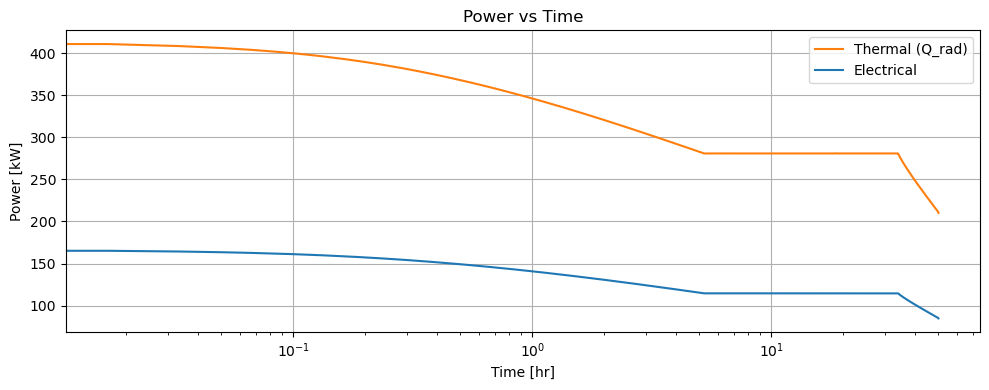

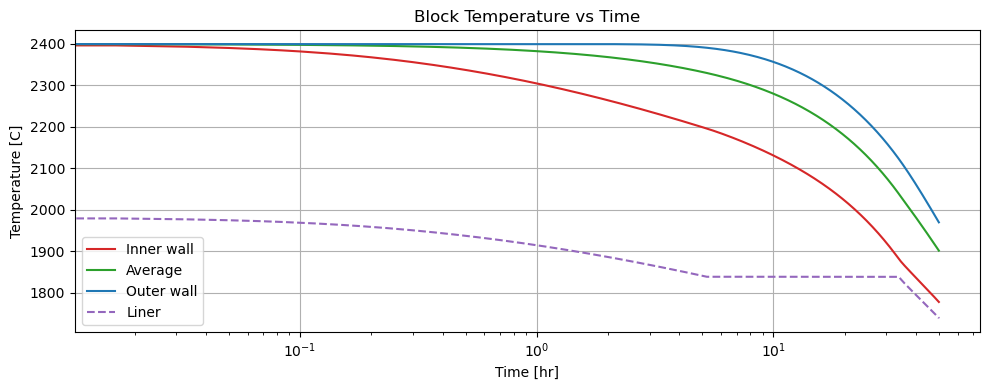

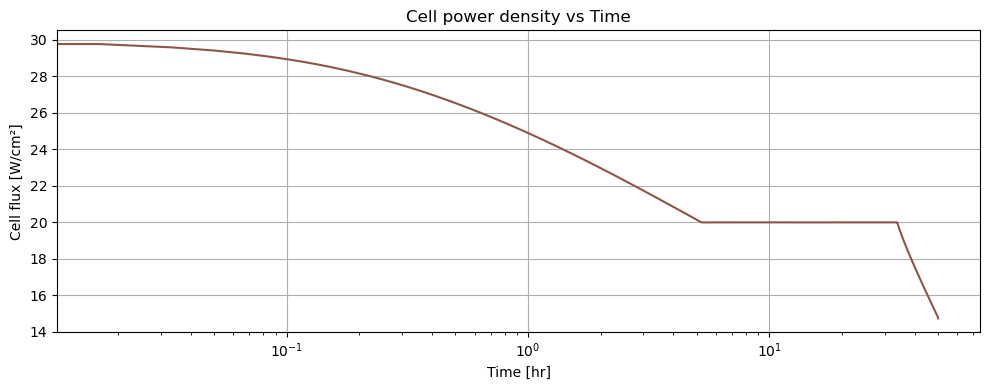

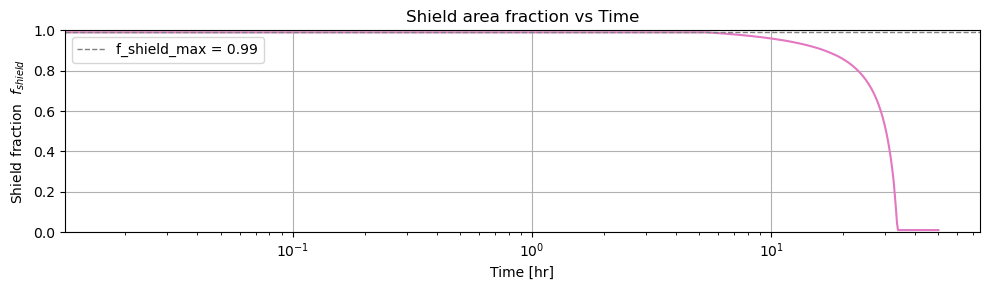

In [18]:
from scipy.integrate import cumulative_trapezoid

time_hr = results['time'] / 3600
# -- State of charge analysis ------------------------------------------------
soc = (results['T_avg'] - T_min) / (T_max - T_min)

print()
print('T_inner - T_avg at SOC milestones:')
for target in [0.75, 0.50, 0.25, 0]:
    idx  = np.argmin(np.abs(soc - target))
    Ti   = results['T_inner'][idx]
    Ta   = results['T_avg'][idx]
    dT   = Ti - Ta
    t_hr = results['time'][idx] / 3600
    print(f'  SOC = {target*100:.0f}%  (t = {t_hr:.1f} hr)  '
          f'T_inner - T_avg = {dT:.1f} K  '
          f'(T_inner = {Ti-273.15:.0f} C, T_avg = {Ta-273.15:.0f} C)')
# -- Power vs time ------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(time_hr, results['Q_rad'] / 1e3, label='Thermal (Q_rad)', color='C1')
ax1.plot(time_hr, results['P_elec'] / 1e3, label='Electrical', color='C0')
ax1.set_xlabel('Time [hr]')
ax1.set_xscale('log')
ax1.set_ylabel('Power [kW]')
ax1.set_title('Power vs Time')
ax1.legend()
ax1.grid(True)
fig1.tight_layout()

# -- Block temperature vs time ------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(10, 4))
ax2.plot(time_hr, results['T_inner'] - 273.15, label='Inner wall', color='C3')
ax2.plot(time_hr, results['T_avg']   - 273.15, label='Average',    color='C2')
ax2.plot(time_hr, results['T_outer'] - 273.15, label='Outer wall', color='C0')
if results['T_liner'].any():
    ax2.plot(time_hr, results['T_liner'] - 273.15, label='Liner', color='C4', linestyle='--')
ax2.set_xlabel('Time [hr]')
ax2.set_xscale('log')
ax2.set_ylabel('Temperature [C]')
ax2.set_title('Block Temperature vs Time')
ax2.legend()
ax2.grid(True)
fig2.tight_layout()

# -- Cumulative electrical / thermal energy -----------------------------------
cum_Q = cumulative_trapezoid(results['Q_rad'],  results['time'], initial=0)
cum_P = cumulative_trapezoid(results['P_elec'], results['time'], initial=0)
with np.errstate(divide='ignore', invalid='ignore'):
    cum_eff = np.where(cum_Q > 0, cum_P / cum_Q * 100, 0.0)


total_Q = cum_Q[-1]
total_P = cum_P[-1]
print(f"Total thermal energy absorbed:   {total_Q/3.6e9:.3f} MWhr")
print(f"Total electrical energy generated: {total_P/3.6e9:.3f} MWhr")
print(f"Overall efficiency:              {total_P/total_Q*100:.2f}%")

# -- Cell flux vs time ------------------------------------------------------
_cell_area_cm2 = 4 * side_len * L * (1 - f_bare) * f_active * 1e4  # cm²
fig3, ax3 = plt.subplots(figsize=(10, 4))
ax3.plot(time_hr, results['Q_cell'] / _cell_area_cm2, color='C5')
ax3.set_xlabel('Time [hr]')
ax3.set_xscale('log')
ax3.set_ylabel('Cell flux [W/cm²]')
ax3.set_title('Cell power density vs Time')
ax3.grid(True)
fig3.tight_layout()

# -- Shade fraction vs time (only when shade is active) -------------------
if shade_bool and results['f_shade'].max() > 0:
    fig4, ax4 = plt.subplots(figsize=(10, 3))
    ax4.plot(time_hr, results['f_shade'], color='C6')
    ax4.axhline(f_shade_max, color='gray', ls='--', lw=1, label=f'f_shade_max = {f_shade_max}')
    ax4.set_xlabel('Time [hr]')
    ax4.set_xscale('log')
    ax4.set_ylabel('Shade fraction  $f_{shade}$')
    ax4.set_title('Shade area fraction vs Time')
    ax4.set_ylim(0, 1)
    ax4.legend()
    ax4.grid(True)
    fig4.tight_layout()

plt.show()


In [9]:
# -- Find area_ratio such that avg Q in pseudo-steady-state = avg_power ------
# Pseudo-steady-state (PSS) begins when T_inner - T_avg stops becoming more
# negative, i.e. at the minimum of delta = T_inner - T_avg (peak gradient).
# We average Q_cell from that point until SOC = 0, and bisect on area_ratio
# until that average equals the design value avg_power.

# ── Load all inputs from YAML (no reliance on other cells' kernel variables) ─
with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_s = _cfg['storage']
_p = _cfg['powerstick']

_end_time    = _cfg['end_time']
_dt_short    = _cfg['dt_short']
_dt_medium   = _cfg['dt_medium']
_dt_long     = _cfg['dt_long']
_sub_steps   = _cfg['sub_steps']
_T_sur       = _cfg['T_sur']
_liner_bool  = _cfg['liner_bool']
_blk_loss    = _cfg['block_heat_loss_bool']

_raw_emis    = _cfg['emissivity_tables'][0]['value']
_emis_table  = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
                for row in _raw_emis]

_avg_flux    = _s['avg_flux']
_duration_hr = _s['duration_hr']
_T_min       = _s['T_min']
_dT_range    = _s['block_temp_range']
_L           = _s['L']
_th_ins      = _s['th_ins']
_num_ax      = _s['num_ax_segments']
_num_rad     = _s['num_rad_segments']

_side_len    = _p['side_len']
_T_ps        = _p['cooling_temp']
#_panel_eff   = _p['panel_efficiency']
_f_bare      = _p['f_bare']
_f_active       = _p['f_active']
_liner_side_len    = _p['liner_side_len']

_sh                = _cfg.get('shade', {})
_shade_bool       = _sh.get('shade_bool', _cfg.get('shade_bool', False))
_shade_side_len   = _sh.get('shade_side_len', None)
_f_shade_min      = _sh.get('f_shade_min', 0.0)
_f_shade_max      = _sh.get('f_shade_max', 0.9)
_N_shades         = _sh.get('N_shades', 2)

# ── Derived quantities ────────────────────────────────────────────────────────
_T_max      = _T_min + _dT_range
_r_ps_eff   = 2 * _side_len / np.pi
_A_ps       = 4 * _side_len * _L           # total powerstick surface area [m^2]
_f_cell     = (1.0 - _f_bare) * _f_active
_f_inact    = (1.0 - _f_bare) * (1.0 - _f_active)
_ps_tmp_    = PowerStick(axial_steps=1, width=_side_len, height=_L,
                        cooling_temp=_T_ps,
                        f_bare=_f_bare, f_active=_f_active,
                        liner_bool=_liner_bool, liner_width=_liner_side_len,
                        emissivity_table=_emis_table)
_inc_bins_, _, _ = _ps_tmp_.incident_energy(_T_min-100, 1 / area_ratio)
_inc_tot_   = sum(_inc_bins_.values())
_f_Q        = sum(
    _inc_bins_[row[0]] / _inc_tot_ * _f_cell * row[1]
    / (_f_bare * row[2] + _f_cell * row[1] + _f_inact * row[3])
    for row in _emis_table)
_e_dens     = storage_rho(_T_min + _dT_range / 2) * storage_cp(_T_min + _dT_range / 2) * _dT_range
_V_block    = _avg_flux * 1e4 * _A_ps * _f_cell / _f_Q * _duration_hr * 3600 / _e_dens
_avg_power  = _avg_flux * 1e4 * _A_ps * _f_cell  # cell-weighted target [W]

print(f"V_block = {_V_block:.3f} m^3  |  avg_power target = {_avg_power/1e3:.1f} kW")
print(f"T_min = {_T_min} K  T_max = {_T_max} K  duration = {_duration_hr} hr")

# ── Bisection objective ───────────────────────────────────────────────────────
def simulate_pss_avg_power(area_ratio):
    r_in_     = _r_ps_eff * area_ratio
    r_out_    = np.sqrt(_V_block / (np.pi * _L) + r_in_**2)
    init_dist = np.full((_num_ax, _num_rad), float(_T_max))
    block_    = GraphiteBlock(init_dist, inner_radius=r_in_, outer_radius=r_out_,
                              length=_L, th_ins=_th_ins)
    pipe_     = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    storage_  = StorageModule(N_pipes=1, Pipe=pipe_, Block=block_,
                              num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                              bypass_range=[0, 1])
    ps_       = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                           cooling_temp=_T_ps,
                           f_bare=_f_bare, f_active=_f_active,
                           liner_bool=_liner_bool, liner_width=_liner_side_len,
                           emissivity_table=_emis_table)
    sim_      = TinlessSimulation(storage_, ps_, T_sur=_T_sur,
                                  block_heat_loss=_blk_loss,
                                  shade_bool=_shade_bool,
                                  shade_side_len=_shade_side_len,
                                  N_shades=_N_shades,
                                  f_shade_min=_f_shade_min,
                                  f_shade_max=_f_shade_max,
                                  nominal_cell_flux=_avg_flux)
    res_      = sim_.run_simulation(end_time=_end_time,
                                dt_short=_dt_short, dt_medium=_dt_medium, dt_long=_dt_long,
                                sub_steps=_sub_steps, dt_short_duration=0)

    delta = res_['T_inner'] - res_['T_avg']
    soc   = (res_['T_avg'] - _T_min) / _dT_range

    #idx_pss  = int(np.argmin(delta))
    idx_pss = int(0)
    t_pss_hr = res_['time'][idx_pss] / 3600

    soc0_mask = np.where(soc <= 0)[0]
    if len(soc0_mask) > 0:
        idx_soc0  = int(soc0_mask[0])
        t_soc0_hr = res_['time'][idx_soc0] / 3600
        soc0_str  = f'SOC=0 @ {t_soc0_hr:.1f} hr'
    else:
        idx_soc0 = len(soc) - 1
        soc0_str = f'SOC={soc[-1]:.2f} at end (never reached 0)'

    if idx_pss >= idx_soc0:
        avg_Q = float(res_['Q_cell'][idx_pss])
    else:
        avg_Q = float(res_['Q_cell'][idx_pss:idx_soc0 + 1].mean())

    print(f'  area_ratio = {area_ratio:6.3f}  '
          f'PSS @ {t_pss_hr:.1f} hr  {soc0_str}  '
          f'avg_Q = {avg_Q/1e3:.2f} kW  (target {_avg_power/1e3:.2f} kW)')
    return avg_Q - _avg_power

# ── Bisection ─────────────────────────────────────────────────────────────────
_pwr_tol = 0.01
_ar_guess = 10.0

print('Searching for area_ratio where avg PSS Q_cell = avg_power...')
f0 = simulate_pss_avg_power(_ar_guess)

if abs(f0) / _avg_power <= _pwr_tol:
    ar_opt = _ar_guess
else:
    if f0 > 0:          # too much heat -> need smaller area_ratio
        ar_hi, f_hi = _ar_guess, f0
        ar_lo = _ar_guess
        while True:
            ar_lo /= 2
            f_lo = simulate_pss_avg_power(ar_lo)
            if f_lo <= 0:
                break
            ar_hi, f_hi = ar_lo, f_lo
    else:               # too little heat -> need larger area_ratio
        ar_lo, f_lo = _ar_guess, f0
        ar_hi = _ar_guess
        while True:
            ar_hi *= 2
            f_hi = simulate_pss_avg_power(ar_hi)
            if f_hi >= 0:
                break
            ar_lo, f_lo = ar_hi, f_hi

    print(f'Bracket: [{ar_lo:.3f}, {ar_hi:.3f}]')

    for _ in range(20):
        ar_mid = (ar_lo + ar_hi) / 2
        f_mid  = simulate_pss_avg_power(ar_mid)
        if abs(f_mid) / _avg_power <= _pwr_tol:
            break
        if f_mid > 0:
            ar_hi = ar_mid
        else:
            ar_lo = ar_mid

    ar_opt = (ar_lo + ar_hi) / 2

_r_in_opt  = _r_ps_eff * ar_opt
_r_out_opt = np.sqrt(_V_block / (np.pi * _L) + _r_in_opt**2)
print()
print(f'Optimal area_ratio = {ar_opt:.3f}')
print(f'  r_in  = {_r_in_opt:.4f} m   D_in  = {2*_r_in_opt:.4f} m')
print(f'  r_out = {_r_out_opt:.4f} m   D_out = {2*_r_out_opt:.4f} m')
print(f'  VF    = {1/ar_opt:.4f}')


V_block = 34.644 m^3  |  avg_power target = 246.0 kW
T_min = 2173 K  T_max = 2673 K  duration = 50 hr
Searching for area_ratio where avg PSS Q_cell = avg_power...


C:\Users\NateColgan\AppData\Local\Temp\ipykernel_104212\3068672506.py:180: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
C:\Users\NateColgan\AppData\Local\Temp\ipykernel_104212\3068672506.py:188: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


  area_ratio = 10.000  PSS @ 0.0 hr  SOC=0.04 at end (never reached 0)  avg_Q = 267.73 kW  (target 246.01 kW)
  area_ratio =  5.000  PSS @ 0.0 hr  SOC=0.14 at end (never reached 0)  avg_Q = 234.59 kW  (target 246.01 kW)
Bracket: [5.000, 10.000]
  area_ratio =  7.500  PSS @ 0.0 hr  SOC=0.08 at end (never reached 0)  avg_Q = 256.35 kW  (target 246.01 kW)
  area_ratio =  6.250  PSS @ 0.0 hr  SOC=0.11 at end (never reached 0)  avg_Q = 247.10 kW  (target 246.01 kW)

Optimal area_ratio = 6.250
  r_in  = 0.5173 m   D_in  = 1.0345 m
  r_out = 1.9858 m   D_out = 3.9716 m
  VF    = 0.1600


In [ ]:
# -- Heating simulation -------------------------------------------------------
# Loads all parameters from YAML. Block starts at T_min (discharged state) and
# is heated to T_min + block_temp_range. heater.area_ratio = D_in / D_heater.

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_end_time  = _cfg['end_time']
_dt        = _cfg['dt_short']  # heating uses the short timestep
_sub_steps = _cfg['sub_steps']
_T_sur     = _cfg['T_sur']
_blk_loss  = _cfg['block_heat_loss_bool']
_liner     = _cfg['liner_bool']

_s = _cfg['storage']
_T_min            = _s['T_min']
_block_temp_range = _s['block_temp_range']
_L                = _s['L']
_th_ins           = _s['th_ins']
_num_ax           = _s['num_ax_segments']
_num_rad          = _s['num_rad_segments']
_avg_flux         = _s['avg_flux']
_duration_hr      = _s['duration_hr']

_p = _cfg['powerstick']
_side_len        = _p['side_len']
_area_ratio      = _p['area_ratio']
_T_ps            = _p['cooling_temp']
_panel_eff       = _p['panel_efficiency']
_f_bare          = _p['f_bare']
_f_active        = _p['f_active']
_liner_side_len  = _p['liner_side_len']

_h               = _cfg['heater']
_he_side_len     = _h['side_len']
_he_T_max        = _h['max_temperature']
_he_P_max        = _h['max_power']
_he_emis         = _h['emissivity']
_he_area_ratio   = _h['area_ratio']  

# -- Derived geometry ----------------------------------------------------------
_T_block_max = _T_min + _block_temp_range
#_r_ps_eff    = 2 * _side_len / np.pi
_r_heater_eff = 2 * _he_side_len / np.pi
_A_ps        = 4 * _side_len * _L
_T_avg_mid   = _T_min + _block_temp_range / 2
_e_dens      = storage_rho(_T_avg_mid) * storage_cp(_T_avg_mid) * _block_temp_range
_V_block     = _avg_flux * _A_ps * 1e4 * _duration_hr * 3600 / _e_dens
_r_in_heat   = _r_heater_eff * _he_area_ratio
_r_out       = np.sqrt(_V_block / (np.pi * _L) + _r_in_heat**2)

# Heater diameter: derived from area_ratio if provided, else read directly
_he_diam = (2 * _r_in_heat / _he_area_ratio) if _he_area_ratio else float(_h['diameter'])

assert _he_diam / 2 < _r_in_heat, (
    f'Heater radius {_he_diam/2:.3f} m >= block inner radius {_r_in_heat:.3f} m -- '
    f'reduce heater diameter or heater area_ratio'
)

print(f'Block:  r_in={_r_in_heat:.3f} m  r_out={_r_out:.3f} m  L={_L} m')
print(f'Temps:  T_init={_T_min} K  T_target={_T_block_max} K')
print(f'Heater: D={_he_diam:.3f} m  T_max={_he_T_max} K  '
      f'P_max={_he_P_max/1e3:.0f} kW  emis={_he_emis}')
print()

# -- Build components ----------------------------------------------------------
_init_dist = np.full((_num_ax, _num_rad), float(_T_min))
_block   = GraphiteBlock(_init_dist, inner_radius=_r_in_heat, outer_radius=_r_out,
                          length=_L, th_ins=_th_ins)
_pipe    = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
_storage = StorageModule(N_pipes=1, Pipe=_pipe, Block=_block,
                          num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                          bypass_range=[0, 1])

# PowerStick needed for TinlessSimulation.__init__; not used during heating
_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
               for row in _raw_emis]
_ps = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                 cooling_temp=_T_ps,
                 f_bare=_f_bare, f_active=_f_active,
                 liner_bool=_liner, liner_width=_liner_side_len,
                 emissivity_table=_emis_table)

_heater = HeatingElement(diameter=_he_diam, max_temperature=_he_T_max,
                          max_power=_he_P_max, emissivity=_he_emis)

# -- Run -----------------------------------------------------------------------
_sim = TinlessSimulation(_storage, _ps, T_sur=_T_sur, block_heat_loss=_blk_loss)

_heat_res = _sim.run_heating_simulation(
    heater         = _heater,
    T_block_max    = _T_block_max,
    end_time       = _end_time,
    dt             = _dt,
    sub_steps      = _sub_steps,
    snap_every     = 3600,
    print_interval = int(3600 / _dt),
)

# -- Summary -------------------------------------------------------------------
_t_hr = _heat_res['time'] / 3600
print(f'\nCharge time:    {_t_hr[-1]:.2f} hr')
print(f'T_avg final:    {_heat_res["T_avg"][-1]:.1f} K  (target {_T_block_max} K)')
print(f'T_heater range: {_heat_res["T_heater"].min():.0f} -- {_heat_res["T_heater"].max():.0f} K')
print(f'Q_heater range: {_heat_res["Q_heater"][1:].min()/1e3:.1f} -- {_heat_res["Q_heater"].max()/1e3:.1f} kW')


In [ ]:
fig, (ax_T, ax_Q) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

_t_hr = _heat_res['time'] / 3600

# -- Temperature plot ---------------------------------------------------------
ax_T.plot(_t_hr, _heat_res['T_inner'], label='T inner wall', color='firebrick')
ax_T.plot(_t_hr, _heat_res['T_avg'],   label='T avg block',  color='steelblue')
ax_T.plot(_t_hr, _heat_res['T_outer'], label='T outer wall', color='seagreen')
if _heat_res['T_liner'].any():
    ax_T.plot(_t_hr, _heat_res['T_liner'], label='T liner', color='mediumpurple', linestyle='--')
ax_T.plot(_t_hr, _heat_res['T_heater'],label='T heater',     color='darkorange', linestyle='--')
ax_T.axhline(_T_block_max, color='grey', linestyle=':', linewidth=1, label=f'T_max = {_T_block_max} K')
ax_T.axhline(_T_min,       color='grey', linestyle='-.', linewidth=1, label=f'T_min = {_T_min} K')
ax_T.set_ylabel('Temperature [K]')
ax_T.set_title('Heating simulation — block and heater temperatures')
ax_T.legend(fontsize=9)
ax_T.grid(True)

# -- Power plot ---------------------------------------------------------------
ax_Q.plot(_t_hr, _heat_res['Q_heater'] / 1e3, color='darkorange', label='Q heater')
ax_Q.axhline(_he_P_max / 1e3, color='grey', linestyle=':', linewidth=1,
             label=f'P_max = {_he_P_max/1e3:.0f} kW')
ax_Q.set_xlabel('Time [hr]')
ax_Q.set_ylabel('Heater power [kW]')
ax_Q.set_title('Heater power delivered')
ax_Q.legend(fontsize=9)
ax_Q.grid(True)

fig.tight_layout()
plt.show()


In [ ]:
# -- Find heater area_ratio such that block reaches T_block_max at end_time ---
# Objective: T_avg(end_time) - T_block_max = 0.
# Larger area_ratio -> larger r_in_heat -> smaller A_h/A_gr ratio
#   -> smaller enclosure resistance -> more heat -> higher f.
# So: f > 0 (overcharged) -> smaller area_ratio; f < 0 -> larger area_ratio.

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_end_time  = _cfg['end_time']
_dt        = _cfg['dt_short']  # heating uses the short timestep
_sub_steps = _cfg['sub_steps']
_T_sur     = _cfg['T_sur']
_blk_loss  = _cfg['block_heat_loss_bool']
_liner     = _cfg['liner_bool']

_s = _cfg['storage']
_T_min            = _s['T_min']
_block_temp_range = _s['block_temp_range']
_L                = _s['L']
_th_ins           = _s['th_ins']
_num_ax           = _s['num_ax_segments']
_num_rad          = _s['num_rad_segments']
_avg_flux         = _s['avg_flux']
_duration_hr      = _s['duration_hr']

_p = _cfg['powerstick']
_side_len  = _p['side_len']
_T_ps      = _p['cooling_temp']
_panel_eff = _p['panel_efficiency']
_f_bare    = _p['f_bare']
_f_active       = _p['f_active']
_liner_side_len = _p['liner_side_len']

_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
               for row in _raw_emis]

_h = _cfg['heater']
_he_side_len = _h['side_len']
_he_T_max    = _h['max_temperature']
_he_P_max    = _h['max_power']
_he_emis     = _h['emissivity']

# -- Derived fixed quantities -------------------------------------------------
_T_block_max   = _T_min + _block_temp_range
_r_heater_eff  = 2 * _he_side_len / np.pi    # effective heater radius (circular equiv)
_he_diam       = 2 * _r_heater_eff            # heater diameter passed to HeatingElement
_A_ps          = 4 * _side_len * _L
_T_avg_mid     = _T_min + _block_temp_range / 2
_e_dens        = storage_rho(_T_avg_mid) * storage_cp(_T_avg_mid) * _block_temp_range
_V_block       = _avg_flux * _A_ps * 1e4 * _duration_hr * 3600 / _e_dens

print(f'V_block = {_V_block:.3f} m^3')
print(f'T_min = {_T_min} K   T_block_max = {_T_block_max} K   end_time = {_end_time/3600:.1f} hr')
print(f'Heater: side_len={_he_side_len} m  D_eff={_he_diam:.4f} m  '
      f'T_max={_he_T_max} K  P_max={_he_P_max/1e3:.0f} kW')
print()

# -- Bisection objective ------------------------------------------------------
def simulate_charge_final_T(area_ratio):
    r_in_      = _r_heater_eff * area_ratio
    r_out_     = np.sqrt(_V_block / (np.pi * _L) + r_in_**2)
    init_dist_ = np.full((_num_ax, _num_rad), float(_T_min))
    block_     = GraphiteBlock(init_dist_, inner_radius=r_in_, outer_radius=r_out_,
                               length=_L, th_ins=_th_ins)
    pipe_      = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    storage_   = StorageModule(N_pipes=1, Pipe=pipe_, Block=block_,
                               num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                               bypass_range=[0, 1])
    ps_        = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                            cooling_temp=_T_ps,
                            f_bare=_f_bare, f_active=_f_active,
                            liner_bool=_liner, liner_width=_liner_side_len,
                            emissivity_table=_emis_table)
    heater_    = HeatingElement(diameter=_he_diam, max_temperature=_he_T_max,
                                max_power=_he_P_max, emissivity=_he_emis)
    sim_       = TinlessSimulation(storage_, ps_, T_sur=_T_sur, block_heat_loss=_blk_loss)
    res_       = sim_.run_heating_simulation(
        heater=heater_, T_block_max=float('inf'),
        end_time=_end_time, dt=_dt, sub_steps=_sub_steps,
    )
    T_final = res_['T_avg'][-1]
    print(f'  area_ratio={area_ratio:6.3f}  r_in={r_in_:.4f} m  '
          f'T_avg_final={T_final:.1f} K  (target {_T_block_max} K)')
    return T_final - _T_block_max

# -- Bisection ----------------------------------------------------------------
_T_tol    = 0.01 * _block_temp_range
_ar_guess = _h['area_ratio']

print('Searching for area_ratio where T_avg(end_time) = T_block_max...')
f0 = simulate_charge_final_T(_ar_guess)

if abs(f0) <= _T_tol:
    ar_opt = _ar_guess
else:
    if f0 > 0:          # overcharged -> need smaller area_ratio
        ar_hi, f_hi = _ar_guess, f0
        ar_lo = _ar_guess
        while True:
            ar_lo /= 2
            f_lo = simulate_charge_final_T(ar_lo)
            if f_lo <= 0:
                break
            ar_hi, f_hi = ar_lo, f_lo
    else:               # undercharged -> need larger area_ratio
        ar_lo, f_lo = _ar_guess, f0
        ar_hi = _ar_guess
        while True:
            ar_hi *= 2
            f_hi = simulate_charge_final_T(ar_hi)
            if f_hi >= 0:
                break
            ar_lo, f_lo = ar_hi, f_hi

    print(f'Bracket: [{ar_lo:.3f}, {ar_hi:.3f}]')

    for _ in range(20):
        ar_mid = (ar_lo + ar_hi) / 2
        f_mid  = simulate_charge_final_T(ar_mid)
        if abs(f_mid) <= _T_tol:
            break
        if f_mid > 0:
            ar_hi = ar_mid
        else:
            ar_lo = ar_mid

    ar_opt = (ar_lo + ar_hi) / 2

_r_in_opt  = _r_heater_eff * ar_opt
_r_out_opt = np.sqrt(_V_block / (np.pi * _L) + _r_in_opt**2)
print()
print(f'Optimal heater area_ratio = {ar_opt:.3f}')
print(f'  r_in  = {_r_in_opt:.4f} m   D_in  = {2*_r_in_opt:.4f} m')
print(f'  r_out = {_r_out_opt:.4f} m   D_out = {2*_r_out_opt:.4f} m')
print(f'  D_in / D_heater = {2*_r_in_opt / _he_diam:.3f}')


In [7]:
import thermal.components as _tc
from scipy.integrate import cumulative_trapezoid

# ── Fixed design parameters ──────────────────────────────────────────────
_avg_flux        = 10          # W/cm^2
_duration_hr     = 50          # hr  (fixed discharge duration)
_side_len        = 0.13        # m
_L               = 3.0         # m
_th_ins          = 0.0         # m
_num_ax          = 2
_num_rad         = 10
_T_ps            = 323         # K
_f_bare          = 0
_f_active        = 0.83
_T_sur            = 300         # K
_dt              = 1200        # s
_sub_steps       = 5
_pwr_tol         = 0.01        # bisection tolerance (fraction of avg_power)
_T_max           = 2173        # K  (block full/maximum temperature)
_liner_side_len  = 0.20        # m  (square side length of tungsten liner)

_r_ps_eff      = 2 * _side_len / np.pi
_avg_power = _avg_flux * 1e4 * 4 * _side_len * _L * (1.0 - _f_bare) * _f_active  # cell-weighted [W]

# ── Sweep parameters ─────────────────────────────────────────────────────
liner_bool_vals = [False, True]           # tungsten liner on/off
#liner_bool_vals = [True]           # tungsten liner on/off
temp_range_vals = [250, 375, 500]         # K  (block operating temperature swing)
#temp_range_vals = [300]         # K  (block operating temperature swing)
bandgap_vals    = [1.24, 1.38, 1.55]     # microns
#bandgap_vals    = [1.55]     # microns

# ── Helpers ───────────────────────────────────────────────────────────────
def _build_and_run(T_max, dT_range, area_ratio, emis_table, liner_bool_):
    """
    Size a graphite storage block and run a full transient discharge simulation.

    T_min = T_max - dT_range.
    Block volume is sized from the required energy; inner radius follows from
    area_ratio = r_in / r_ps_eff; outer radius derived from V_block and r_in.
    """
    T_min     = T_max - dT_range
    T_avg_mid = T_min + dT_range / 2
    e_dens_   = storage_rho(T_avg_mid) * storage_cp(T_avg_mid) * dT_range
    f_cell_      = (1.0 - _f_bare) * _f_active
    f_inact_     = (1.0 - _f_bare) * (1.0 - _f_active)
    ps_tmp_      = PowerStick(axial_steps=1, width=_side_len, height=_L,
                             cooling_temp=_T_ps,
                             f_bare=_f_bare, f_active=_f_active,
                             liner_bool=liner_bool_, liner_width=_liner_side_len,
                             emissivity_table=emis_table)
    inc_bins_, _, _ = ps_tmp_.incident_energy(T_min, 1.0)
    inc_tot_     = sum(inc_bins_.values())
    f_Q_         = sum(
        inc_bins_[row[0]] / inc_tot_ * f_cell_ * row[1]
        / (_f_bare * row[2] + f_cell_ * row[1] + f_inact_ * row[3])
        for row in emis_table)
    tot_power_   = _avg_flux * 1e4 * 4 * _side_len * _L * f_cell_ / f_Q_
    V_blk_    = tot_power_ * _duration_hr * 3600 / e_dens_
    r_in_     = _r_ps_eff * area_ratio
    r_out_    = np.sqrt(V_blk_ / (np.pi * _L) + r_in_**2)

    init_dist_ = np.full((_num_ax, _num_rad), float(T_max))
    block_  = GraphiteBlock(init_dist_, inner_radius=r_in_, outer_radius=r_out_,
                            length=_L, th_ins=_th_ins)
    pipe_   = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    stor_   = StorageModule(N_pipes=1, Pipe=pipe_, Block=block_,
                            num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                            bypass_range=[0, 1])
    ps_     = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                         cooling_temp=_T_ps,
                         f_bare=_f_bare, f_active=_f_active,
                         liner_bool=liner_bool_, liner_width=_liner_side_len,
                         emissivity_table=emis_table)
    sim_    = TinlessSimulation(stor_, ps_, T_sur=_T_sur, block_heat_loss=False)
    res_    = sim_.run_simulation(end_time=_duration_hr * 3600, dt=_dt, sub_steps=_sub_steps)
    return res_, r_out_

def _pss_avg_q(res_, dT_range, T_max):
    """
    Compute average cell heat flux over the pseudo-steady-state window.
    PSS onset fixed at t=0; window ends when SOC drops to zero.
    """
    T_min    = T_max - dT_range
    soc      = (res_['T_avg'] - T_min) / dT_range
    idx_pss  = int(0)
    soc0     = np.where(soc <= 0)[0]
    idx_soc0 = int(soc0[0]) if len(soc0) else len(soc) - 1
    if idx_pss >= idx_soc0:
        return float(res_['Q_cell'][idx_pss])
    return float(res_['Q_cell'][idx_pss:idx_soc0 + 1].mean())

# ── Main sweep ───────────────────────────────────────────────────────────
sweep_results = {}
total = len(liner_bool_vals) * len(bandgap_vals) * len(temp_range_vals)
n = 0

for liner_bool_ in liner_bool_vals:
    for bg_val in bandgap_vals:
        emis_table_bg = [
            ((0.1,    bg_val), 0.9,  0.1, 0.1),
            ((bg_val, 20.0),   0.05, 0.1, 0.1),
        ]
        for dT_range in temp_range_vals:
            n += 1
            print(f'[{n}/{total}] liner={liner_bool_}  dT={dT_range}K  T_min={_T_max - dT_range}K  bg={bg_val}um  -- bisecting area_ratio')

            try:
                def _f(ar, _Tmax=_T_max, _dT=dT_range, _emis=emis_table_bg, _lb=liner_bool_):
                    res_, _ = _build_and_run(_Tmax, _dT, ar, _emis, _lb)
                    q = _pss_avg_q(res_, _dT, _Tmax)
                    print(f'    ar={ar:.3f}  avg_Q={q/1e3:.1f} kW  (target {_avg_power/1e3:.0f} kW)')
                    return q - _avg_power

                f0 = _f(10.0)
                if abs(f0) / _avg_power <= _pwr_tol:
                    ar_opt = 10.0
                else:
                    if f0 > 0:
                        ar_hi, f_hi = 10.0, f0
                        ar_lo = 10.0
                        while True:
                            ar_lo /= 2
                            f_lo = _f(ar_lo)
                            if f_lo <= 0:
                                break
                            ar_hi, f_hi = ar_lo, f_lo
                    else:
                        ar_lo, f_lo = 10.0, f0
                        ar_hi = 10.0
                        while True:
                            ar_hi *= 2
                            f_hi = _f(ar_hi)
                            if f_hi >= 0:
                                break
                            ar_lo, f_lo = ar_hi, f_hi

                    for _ in range(20):
                        ar_mid = (ar_lo + ar_hi) / 2
                        f_mid  = _f(ar_mid)
                        if abs(f_mid) / _avg_power <= _pwr_tol:
                            break
                        if f_mid > 0:
                            ar_hi = ar_mid
                        else:
                            ar_lo = ar_mid
                    ar_opt = (ar_lo + ar_hi) / 2

                res_opt, r_out_opt = _build_and_run(_T_max, dT_range, ar_opt, emis_table_bg, liner_bool_)
                Q  = res_opt['Q_rad']
                Q_cell = res_opt['Q_cell']
                Pe = res_opt['P_elec']
                Ti = res_opt['T_inner']
                Ta = res_opt['T_avg']
                t  = res_opt['time']
                cum_Q = cumulative_trapezoid(Q,  t, initial=0)
                cum_Q_cell = cumulative_trapezoid(Q_cell, t, initial=0)
                cum_P = cumulative_trapezoid(Pe, t, initial=0)
                eff   = cum_P[-1] / cum_Q[-1] * 100 if cum_Q[-1] > 0 else 0.0
                eff_cell = cum_P[-1] / cum_Q_cell[-1] * 100 if cum_Q_cell[-1] > 0 else 0.0

                sweep_results[(dT_range, bg_val, liner_bool_)] = dict(
                    area_ratio = ar_opt,
                    r_out      = r_out_opt,
                    peak_dT    = float(np.max(Ta - Ti)),
                    peak_power = float(np.max(Q)) / 1e3,
                    min_power  = float(np.min(Q)) / 1e3,
                    efficiency = eff,
                    efficiency_cell = eff_cell,
                    avg_cell_flux  = float(Q_cell.mean()) / (4 * _side_len * _L * (1.0 - _f_bare) * _f_active * 1e4),
                )
                print(f'    -> ar_opt={ar_opt:.3f}  r_out={r_out_opt:.3f}m  '
                      f'peak_Q={np.max(Q)/1e3:.0f}kW  eff={eff:.1f}%')
            except Exception as e:
                print(f'    ERROR ({type(e).__name__}): {e} — skipping')

print('Sweep complete.')


[1/18] liner=False  dT=250K  T_min=1923K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[2/18] liner=False  dT=375K  T_min=1798K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[3/18] liner=False  dT=500K  T_min=1673K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[4/18] liner=False  dT=250K  T_min=1923K  bg=1.38um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[5/18] liner=False  dT=375K  T_min=1798K  bg=1.38um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[6/18] liner=False  dT=500K  T_min=1673K  bg=1.38um  -- bisecting area

In [ ]:
dT_colors    = plt.cm.plasma(np.linspace(0.15, 0.85, len(temp_range_vals)))
liner_styles = {False: '-', True: '--'}
liner_labels = {False: 'no liner', True: 'W liner'}

fig, axes = plt.subplots(4, 2, figsize=(12, 18))

ax_ar,  ax_rout    = axes[0]
ax_eff,  ax_pwr     = axes[1]
ax_eff_c, ax_min_pwr = axes[2]
ax_bl2, ax_bl3     = axes[3]

for ci, dT_range in enumerate(temp_range_vals):
    for liner_bool_ in liner_bool_vals:
        try:
            lbl    = f'ΔT={dT_range}K, {liner_labels[liner_bool_]}'
            kwargs = dict(color=dT_colors[ci], linestyle=liner_styles[liner_bool_],
                          marker='o', label=lbl)

            ax_ar.plot(      bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['area_ratio'] for bg in bandgap_vals], **kwargs)
            ax_rout.plot(    bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['r_out']      for bg in bandgap_vals], **kwargs)
            #ax_dT.plot(      bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['peak_dT']    for bg in bandgap_vals], **kwargs)
            ax_pwr.plot(     bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['peak_power'] / (4 * _side_len * _L * (1 - _f_bare) * _f_active * 10) for bg in bandgap_vals], **kwargs)
            ax_min_pwr.plot( bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['min_power']  / (4 * _side_len * _L * (1 - _f_bare) * _f_active * 10) for bg in bandgap_vals], **kwargs)
            ax_eff.plot(   bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['efficiency'] for bg in bandgap_vals], **kwargs)
            ax_eff_c.plot(   bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['efficiency_cell'] for bg in bandgap_vals], **kwargs)
            ax_bl2.plot(     bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['avg_cell_flux']    for bg in bandgap_vals], **kwargs)
        except KeyError:
            pass

ax_ar.set_ylabel('Optimal area ratio')
ax_ar.set_title('Optimal area ratio')
ax_rout.set_ylabel('Outer radius [m]')
ax_rout.set_title('Block outer radius')
#ax_dT.set_ylabel('Peak ΔT (inner − avg) [K]')
#ax_dT.set_title('Peak inner wall dT')
ax_pwr.set_ylabel('Peak power density [W/cm²]')
ax_pwr.set_title('Peak power (start of discharge)')
ax_min_pwr.set_ylabel('Min power density [W/cm²]')
ax_min_pwr.set_title('Min power (end of discharge)')
ax_eff.set_ylabel('Overall efficiency [%]')
ax_eff.set_title('Cumulative elec / thermal')
ax_eff_c.set_ylabel('Cell efficiency [%]')
ax_eff_c.set_title('Cumulative elec / cell thermal')
ax_bl2.set_ylabel('Avg cell flux [W/cm²]')
ax_bl2.set_title('Average cell power density')

for ax in [ax_ar, ax_rout, ax_pwr, ax_min_pwr, ax_eff, ax_eff_c, ax_bl2]:
    ax.set_xlabel('Bandgap [μm]')
    ax.grid(True)

for ax in [ax_bl3]:
    ax.set_visible(False)

ax_ar.legend(fontsize=9)
fig.suptitle(
    f'Parametric sweep  |  f_bare={_f_bare}  T_max={_T_max} K  dur={_duration_hr} hr  avg_flux={_avg_flux} W/cm²',
    fontsize=10,
)
fig.tight_layout()
plt.show()


r_ps_eff  = 8.28 cm
r_liner   = 19.10 cm
r_shield  = 20.37 cm
r_in      = 63.70 cm
A_cell    = 15600.0 cm²


C:\Users\NateColgan\AppData\Local\Temp\ipykernel_70932\3801295365.py:179: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
C:\Users\NateColgan\AppData\Local\Temp\ipykernel_70932\3801295365.py:187: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


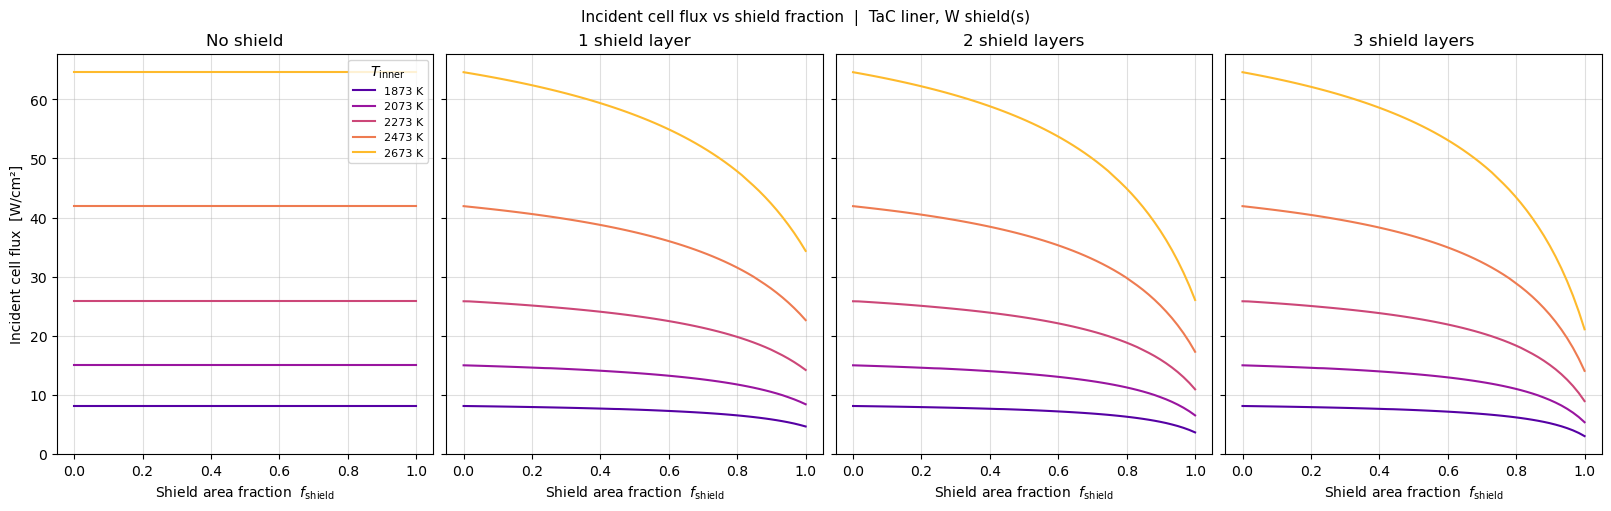


Cell flux [W/cm²] at f_shield = 0.5
     T_hot  N=0  N=1  N=2  N=3
      1873   8.15   7.57   7.52   7.49
      2073  15.03  13.77  13.66  13.60
      2273  25.86  23.45  23.21  23.10
      2473  41.94  37.66  37.20  36.99
      2673  64.59  57.55  56.77  56.40


In [40]:
# ── Scratch: shade sensitivity ── incident cell flux vs f_shade ─────────────
# Self-contained: adjust any input below.
# Depends on: TinlessSimulation class defined in cell 03dd9a23 (run that cell first).
import numpy as np
import matplotlib.pyplot as plt

# ── Inputs ────────────────────────────────────────────────────────────────────
side_len        = 0.13    # powerstick square side [m]
liner_side_len  = 0.30    # liner square side [m]
shade_side_len = 0.32    # shade square side [m]  (r_shade must lie between r_liner and r_in)
r_in            = 0.637    # graphite inner-wall effective radius [m]
L               = 3.0     # axial length [m]
f_bare          = 0.0
f_active        = 1.0

band_gap = 1.24           # PV bandgap [μm]
emissivity_table = [
    ((0.1,      band_gap), 0.9,  0.10, 0.10),
    ((band_gap, 20.0    ), 0.05, 0.10, 0.10),
]

T_hot_vals     = [1873, 2073, 2273, 2473, 2673]  # graphite inner-wall temperatures [K]
N_shades_vals = [0, 1, 2, 3]                    # number of shade layers
f_shade_arr   = np.linspace(0, 1, 60)            # shade area fractions to sweep

# ── Derived geometry ──────────────────────────────────────────────────────────
r_ps_eff = 2 * side_len / np.pi
r_liner  = 2 * liner_side_len / np.pi
r_shade = 2 * shade_side_len / np.pi

assert r_liner < r_shade < r_in, (
    f"Need r_liner ({r_liner*100:.1f} cm) < r_shade ({r_shade*100:.1f} cm)"
    f" < r_in ({r_in*100:.1f} cm)"
)

VF_gr_liner   = r_liner  / r_in
VF_liner_ps   = r_ps_eff / r_liner
VF_gr_shade  = r_shade / r_in
VF_shade_lin = r_liner  / r_shade

A_ps         = 4 * side_len * L
A_liner_seg  = 2 * np.pi * r_liner  * L
A_shade_seg = 2 * np.pi * r_shade * L
A_cell_cm2   = 4 * side_len * L * (1 - f_bare) * f_active * 1e4

print(f"r_ps_eff  = {r_ps_eff*100:.2f} cm")
print(f"r_liner   = {r_liner*100:.2f} cm")
print(f"r_shade  = {r_shade*100:.2f} cm")
print(f"r_in      = {r_in*100:.2f} cm")
print(f"A_cell    = {A_cell_cm2:.1f} cm\u00b2")

# ── Mock sim object for TinlessSimulation.spectral_net_radiation ──────────────
# spectral_net_radiation is an instance method; calling it as
# TinlessSimulation.spectral_net_radiation(mock, T_hot, f_shade=fs)
# is idiomatic Python for unbound method calls.
class _M:
    pass

def _make_sim(N):
    m = _M()
    m.powerstick              = _M()
    m.powerstick.emissivity_table = emissivity_table
    m.powerstick.liner_bool   = True
    m.powerstick.f_bare       = f_bare
    m.powerstick.f_active     = f_active
    m.VF                      = VF_gr_liner
    m.A_ps_seg                = A_ps
    m.N_shades               = max(N, 1)   # formula needs >= 1 when shade is active
    m.shade_bool             = (N > 0)
    m.VF_gr_liner             = VF_gr_liner
    m.VF_liner_ps             = VF_liner_ps
    m.A_liner_seg             = A_liner_seg
    m.VF_gr_shade            = VF_gr_shade  if N > 0 else None
    m.VF_shade_lin           = VF_shade_lin if N > 0 else None
    m.A_shade_seg            = A_shade_seg  if N > 0 else None
    return m

# ── Sweep ─────────────────────────────────────────────────────────────────────
flux = {}   # (N, T_hot) -> flux array over f_shade_arr
for N in N_shades_vals:
    sim = _make_sim(N)
    for T_hot in T_hot_vals:
        vals = []
        for fs in f_shade_arr:
            Q_ps, _ = TinlessSimulation.spectral_net_radiation(sim, T_hot, f_shade=fs)
            vals.append(Q_ps / A_cell_cm2)
        flux[(N, T_hot)] = np.array(vals)

# ── Plot: one subplot per N_shades ──────────────────────────────────────────
colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(T_hot_vals)))
fig, axes = plt.subplots(1, len(N_shades_vals), figsize=(16, 5), sharey=True,
                         constrained_layout=True)

for ax, N in zip(axes, N_shades_vals):
    for color, T_hot in zip(colors, T_hot_vals):
        ax.plot(f_shade_arr, flux[(N, T_hot)], color=color, label=f'{T_hot} K')
    title = 'No shade' if N == 0 else f'{N} shade layer{"s" if N > 1 else ""}'
    ax.set_title(title)
    ax.set_xlabel('Shade area fraction  $f_\\mathrm{shade}$')
    ax.grid(True, alpha=0.4)

axes[0].set_ylabel('Incident cell flux  [W/cm\u00b2]')
axes[0].legend(title='$T_\\mathrm{inner}$', fontsize=8)
fig.suptitle('Incident cell flux vs shade fraction  |  TaC liner, W shade(s)', fontsize=11)
plt.show()


# ── Summary table ─────────────────────────────────────────────────────────────
fs_ref = 0.5
i_ref  = np.argmin(np.abs(f_shade_arr - fs_ref))
print(f"\nCell flux [W/cm\u00b2] at f_shade = {fs_ref}")
header = '  '.join(f'N={N}' for N in N_shades_vals)
print(f"{'T_hot':>10}  {header}")
for T_hot in T_hot_vals:
    vals = '  '.join(f'{flux[(N,T_hot)][i_ref]:>5.2f}' for N in N_shades_vals)
    print(f"{T_hot:>10}  {vals}")


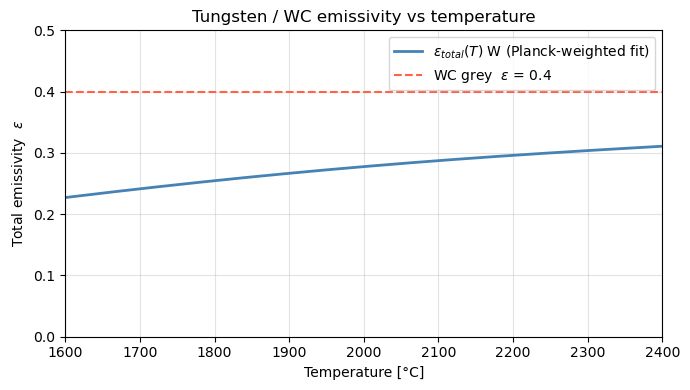

   T [C]     T [K]   eps_W_total   eps_WC_grey
    1600      1873        0.2271        0.4000
    1700      1973        0.2414        0.4000
    1800      2073        0.2546        0.4000
    1900      2173        0.2667        0.4000
    2000      2273        0.2776        0.4000
    2100      2373        0.2874        0.4000
    2200      2473        0.2960        0.4000
    2300      2573        0.3038        0.4000
    2400      2673        0.3109        0.4000


In [6]:
# -- Scratch: tungsten emissivity vs temperature --------------------------------
import numpy as np
import matplotlib.pyplot as plt
from thermal.properties import w_emis_total, wc_emis_grey

T_C = np.linspace(1600, 2400, 300)
T_K = T_C + 273.15
eps = np.array([w_emis_total(T) for T in T_K])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(T_C, eps, color='steelblue', lw=2, label=r'$\varepsilon_{total}(T)$ W (Planck-weighted fit)')
ax.axhline(wc_emis_grey(0), color='tomato', ls='--', lw=1.5, label=f'WC grey  $\\varepsilon$ = {wc_emis_grey(0)}')
ax.set_xlabel('Temperature [°C]')
ax.set_ylabel(r'Total emissivity  $\varepsilon$')
ax.set_title('Tungsten / WC emissivity vs temperature')
ax.set_xlim(1600, 2400)
ax.set_ylim(0, 0.5)
ax.legend()
ax.grid(True, alpha=0.35)
fig.tight_layout()
plt.show()

print(f"{'T [C]':>8}  {'T [K]':>8}  {'eps_W_total':>12}  {'eps_WC_grey':>12}")
for Tc in [1600, 1700, 1800, 1900, 2000, 2100, 2200, 2300, 2400]:
    print(f"{Tc:8d}  {Tc+273.15:8.0f}  {w_emis_total(Tc + 273.15):12.4f}  {wc_emis_grey(Tc + 273.15):12.4f}")


Integration done.
Fit rms=0.00106  max_err=0.00378
Coefficients: [ 0.00570748 -0.0359372   0.04024944  0.11090748 -0.09849622  0.06877972]


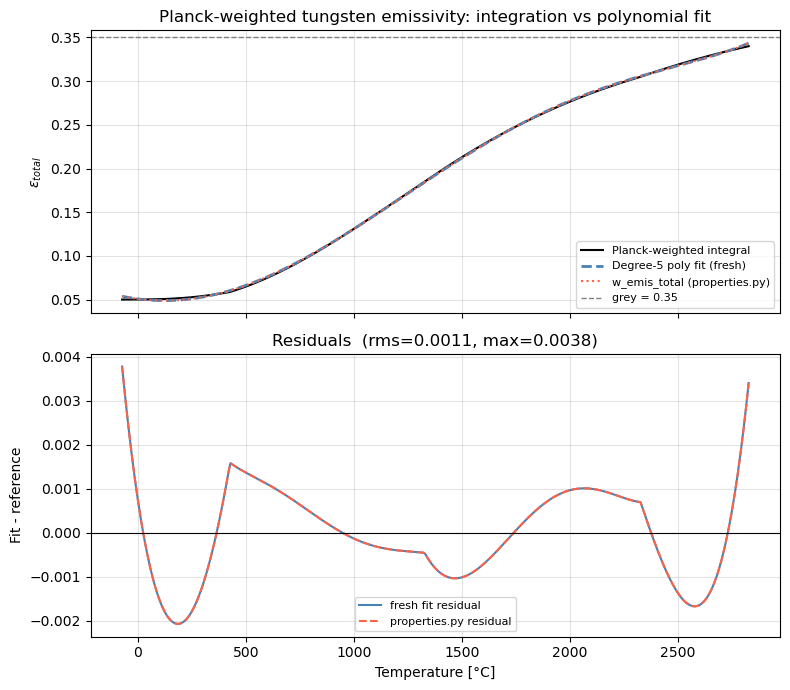

In [14]:
# -- Scratchwork: how w_emis_total was derived from w_emis_spectral -----------
# Planck-weighted total emissivity:
#   eps_total(T) = integral( eps(lam,T) * B(lam,T) dlam ) / integral( B(lam,T) dlam )
# Numerator integrates over the w_emis_spectral table range (0.26-4.9 um).
# Denominator integrates over the full Planck spectrum so low-T is correctly weighted.
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from thermal.properties import w_emis_spectral, w_emis_total

C1 = 3.7418e-16   # 2*h*c^2  [W*m^2]
C2 = 1.4388e-2    # h*c/k_B  [m*K]

def planck(lam_m, T):
    return C1 / (lam_m**5 * (np.exp(C2 / (lam_m * T)) - 1))

def w_emis_planck_weighted(T):
    lam_min = 0.1e-6   # [m]  (just inside table bounds)
    lam_max = 999e-6    # [m]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        numer, _ = quad(lambda lam: w_emis_spectral(T, lam*1e6) * planck(lam, T),
                        lam_min, lam_max, limit=500)
        denom, _ = quad(lambda lam: planck(lam, T),
                        lam_min, lam_max, limit=500)   # full spectrum
    return numer / denom

# -- Compute reference values -------------------------------------------------
T_grid  = np.linspace(200, 3100, 400)
eps_ref = np.array([w_emis_planck_weighted(T) for T in T_grid])
print('Integration done.')

# -- Fit degree-5 polynomial in t = T/1000 -----------------------------------
t_grid = T_grid / 1000.0
coeffs = np.polyfit(t_grid, eps_ref, 5)
eps_fit = np.polyval(coeffs, t_grid)
rms     = np.sqrt(np.mean((eps_fit - eps_ref)**2))
maxerr  = np.max(np.abs(eps_fit - eps_ref))
print(f'Fit rms={rms:.5f}  max_err={maxerr:.5f}')
print('Coefficients:', coeffs)

# -- Compare fit to the hardcoded w_emis_total --------------------------------
eps_hardcoded = np.array([w_emis_total(T) for T in T_grid])

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax = axes[0]
ax.plot(T_grid - 273.15, eps_ref,       'k',           lw=1.5, label='Planck-weighted integral')
ax.plot(T_grid - 273.15, eps_fit,        'steelblue',   lw=2,   ls='--', label='Degree-5 poly fit (fresh)')
ax.plot(T_grid - 273.15, eps_hardcoded,  'tomato',      lw=1.5, ls=':',  label='w_emis_total (properties.py)')
ax.axhline(0.35, color='gray', ls='--', lw=1, label='grey = 0.35')
ax.set_ylabel(r'$\varepsilon_{total}$')
ax.set_title('Planck-weighted tungsten emissivity: integration vs polynomial fit')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.35)

ax = axes[1]
ax.plot(T_grid - 273.15, eps_fit - eps_ref,       'steelblue', lw=1.5, label='fresh fit residual')
ax.plot(T_grid - 273.15, eps_hardcoded - eps_ref, 'tomato',    lw=1.5, ls='--', label='properties.py residual')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Temperature [°C]')
ax.set_ylabel('Fit - reference')
ax.set_title(f'Residuals  (rms={rms:.4f}, max={maxerr:.4f})')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.35)

fig.tight_layout()
plt.show()


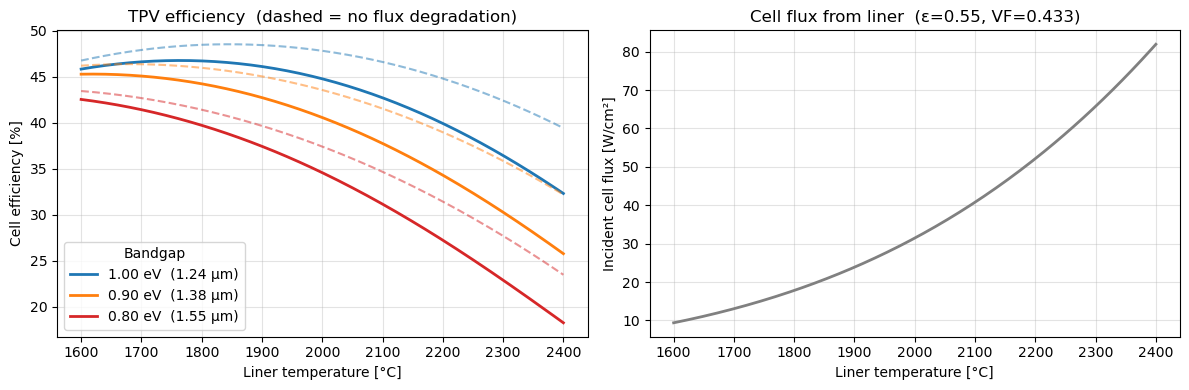

In [5]:
# -- Cell efficiency vs emitter temperature — with flux degradation -----------
# Flux calculated via PowerStick.incident_energy() so powerstick emissivity
# table and view factor are applied correctly (not a blackbody assumption).
import yaml, numpy as np, matplotlib.pyplot as plt
from thermal.properties import panel_efficiency

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_p              = _cfg['powerstick']
_s              = _cfg['storage']
_side_len       = _p['side_len']
_area_ratio     = _p['area_ratio']
_f_bare         = _p['f_bare']
_f_active       = _p['f_active']
_liner_side_len = _p['liner_side_len']
_L              = _s['L']
_num_ax         = _s['num_ax_segments']

_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(r[0]), float(r[1]), float(r[2]), float(r[3])) for r in _raw_emis]

_r_ps_eff    = 2 * _side_len / np.pi
_r_in        = _r_ps_eff * _area_ratio
_r_liner     = 2 * _liner_side_len / np.pi
_VF_liner_ps = _r_ps_eff / _r_liner

# Build a single-step PowerStick (1 axial segment = full length)
_ps = PowerStick(axial_steps=1, width=_side_len, height=_L,
                 cooling_temp=300, f_bare=_f_bare, f_active=_f_active,
                 liner_bool=True, liner_width=_liner_side_len,
                 emissivity_table=_emis_table)

bandgaps = [1.24, 1.38, 1.55]
bg_eV    = [1.2398 / bg for bg in bandgaps]
T_C      = np.linspace(1600, 2400, 200)
T_K      = T_C + 273.15

# Compute flux_wcm2 at each temperature using incident_energy — same formula
# as generate_electricity_step so powerstick emissivity is properly applied.
def _flux_wcm2(T):
    inc_bins, _, _ = _ps.incident_energy(T, _VF_liner_ps)
    absorbed_cell = 0.0
    for i, (wr, ea, eb, ei) in enumerate(_emis_table):
        avg = _f_bare*eb + (1-_f_bare)*_f_active*ea + (1-_f_bare)*(1-_f_active)*ei
        if avg > 0:
            absorbed_cell += inc_bins[wr] * (1-_f_bare) * _f_active * ea / avg
    cell_flux_W = absorbed_cell * _ps.A_step
    return cell_flux_W / (_ps.A_step * (1-_f_bare) * _f_active * 1e4)

flux_wcm2 = np.array([_flux_wcm2(T) for T in T_K])

colors = ['C0', 'C1', 'C3']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
for bg, eV, col in zip(bandgaps, bg_eV, colors):
    eff_base = np.array([panel_efficiency(bg, T) * 100 for T in T_K])
    eff_flux = np.array([panel_efficiency(bg, T, flux=f) * 100 for T, f in zip(T_K, flux_wcm2)])
    ax.plot(T_C, eff_base, color=col, lw=1.5, ls='--', alpha=0.5)
    ax.plot(T_C, eff_flux, color=col, lw=2, label=f'{eV:.2f} eV  ({bg} μm)')

ax.set_xlabel('Liner temperature [°C]')
ax.set_ylabel('Cell efficiency [%]')
ax.set_title('TPV efficiency  (dashed = no flux degradation)')
ax.legend(title='Bandgap')
ax.grid(True, alpha=0.35)

ax2 = axes[1]
ax2.plot(T_C, flux_wcm2, color='gray', lw=2)
ax2.set_xlabel('Liner temperature [°C]')
ax2.set_ylabel('Incident cell flux [W/cm²]')
ax2.set_title(f'Cell flux from liner  (ε=0.55, VF={_VF_liner_ps:.3f})')
ax2.grid(True, alpha=0.35)

fig.tight_layout()
plt.show()


[1/24] N=0  T_min=1973  T_range=250  r_out=2.878 m


C:\Users\NateColgan\AppData\Local\Temp\ipykernel_44520\3068672506.py:180: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
C:\Users\NateColgan\AppData\Local\Temp\ipykernel_44520\3068672506.py:188: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


[2/24] N=1  T_min=1973  T_range=250  r_out=2.878 m
[3/24] N=2  T_min=1973  T_range=250  r_out=2.878 m
[4/24] N=3  T_min=1973  T_range=250  r_out=2.878 m
[5/24] N=0  T_min=1973  T_range=500  r_out=2.117 m
[6/24] N=1  T_min=1973  T_range=500  r_out=2.117 m
[7/24] N=2  T_min=1973  T_range=500  r_out=2.117 m
[8/24] N=3  T_min=1973  T_range=500  r_out=2.117 m
[9/24] N=0  T_min=2073  T_range=250  r_out=2.878 m
[10/24] N=1  T_min=2073  T_range=250  r_out=2.878 m
[11/24] N=2  T_min=2073  T_range=250  r_out=2.878 m
[12/24] N=3  T_min=2073  T_range=250  r_out=2.878 m
[13/24] N=0  T_min=2073  T_range=500  r_out=2.117 m
[14/24] N=1  T_min=2073  T_range=500  r_out=2.117 m
[15/24] N=2  T_min=2073  T_range=500  r_out=2.117 m
[16/24] N=3  T_min=2073  T_range=500  r_out=2.117 m
[17/24] N=0  T_min=2173  T_range=250  r_out=2.878 m
[18/24] N=1  T_min=2173  T_range=250  r_out=2.878 m
[19/24] N=2  T_min=2173  T_range=250  r_out=2.878 m
[20/24] N=3  T_min=2173  T_range=250  r_out=2.878 m
[21/24] N=0  T_min=2

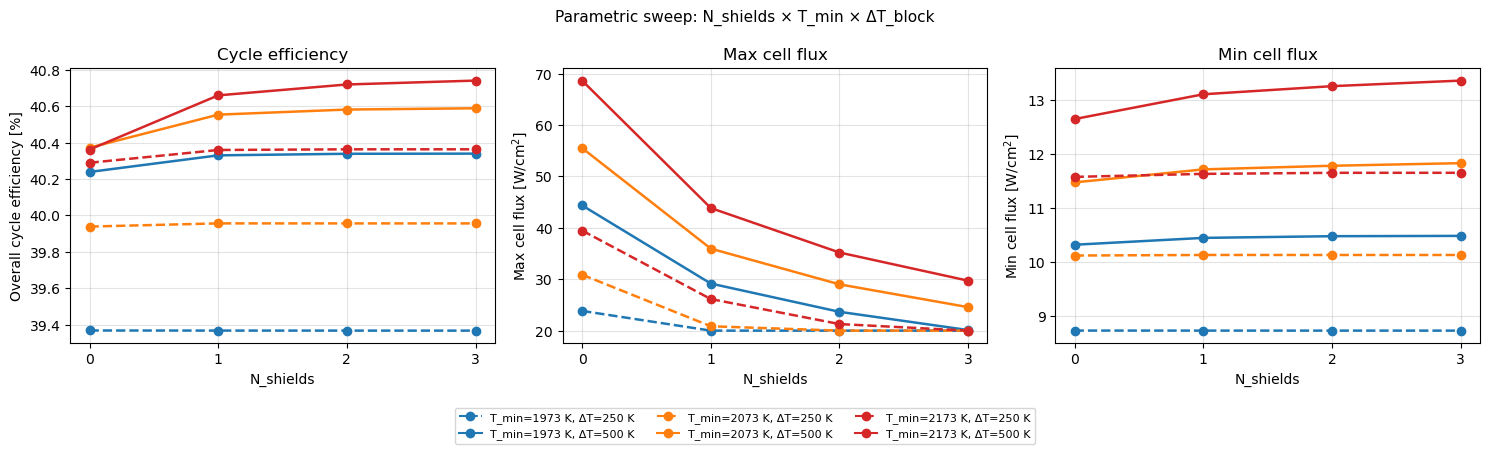

In [8]:
# -- Scratch: parametric sweep  N_shades x T_min x T_range -----------------
# Self-contained: reads config from YAML, rebuilds geometry for each case.
# Sweep: N_shades=[0,1,2,3], T_min=[1973,2073,2173], T_range=[250,500]
# Metrics: overall cycle efficiency, max cell flux, min cell flux
import yaml, numpy as np, matplotlib.pyplot as plt
from itertools import product

# -- Load YAML ----------------------------------------------------------------
with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_end_time          = _cfg['end_time']
_dt_short          = _cfg['dt_short']
_dt_medium         = _cfg['dt_medium']
_dt_long           = _cfg['dt_long']
_dt_short_duration = _cfg.get('dt_short_duration', 3600)
_sub_steps         = _cfg['sub_steps']
_T_sur             = _cfg['T_sur']
_liner_bool        = _cfg['liner_bool']
_block_heat_loss   = _cfg['block_heat_loss_bool']

_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(r[0]), float(r[1]), float(r[2]), float(r[3])) for r in _raw_emis]

_s            = _cfg['storage']
_avg_flux     = _s['avg_flux']
_duration_hr  = _s['duration_hr']
_L            = _s['L']
_th_ins       = _s['th_ins']
_num_ax       = _s['num_ax_segments']
_num_rad      = _s['num_rad_segments']

_p              = _cfg['powerstick']
_side_len       = _p['side_len']
_area_ratio     = _p['area_ratio']
_f_bare         = _p['f_bare']
_f_active       = _p['f_active']
_T_ps           = _p['cooling_temp']
_liner_side_len = _p['liner_side_len']

_sh              = _cfg.get('shade', {})
_shade_side_len = _sh.get('shade_side_len', None)
_f_shade_min    = _sh.get('f_shade_min', 0.0)
_f_shade_max    = _sh.get('f_shade_max', 0.9)

# -- Sweep parameters ---------------------------------------------------------
_N_sweep      = [0, 1, 2, 3]
_T_min_sweep  = [1973, 2073, 2173]
_T_range_sweep = [250, 500]

# -- Fixed geometry (doesn't depend on sweep params) --------------------------
_r_ps_eff   = 2 * _side_len / np.pi
_r_in       = _r_ps_eff * _area_ratio
_A_ps       = 4 * _side_len * _L
_f_cell_    = (1.0 - _f_bare) * _f_active
_f_inact_   = (1.0 - _f_bare) * (1.0 - _f_active)
_cell_area_cm2 = _A_ps * _f_cell_ * 1e4

_ps_tmp_ = PowerStick(axial_steps=1, width=_side_len, height=_L,
                      cooling_temp=_T_ps, f_bare=_f_bare, f_active=_f_active,
                      liner_bool=_liner_bool, liner_width=_liner_side_len,
                      emissivity_table=_emis_table)
_inc_bins_, _, _ = _ps_tmp_.incident_energy(_T_min_sweep[0] - 100, 1 / _area_ratio)
_inc_tot_ = sum(_inc_bins_.values())
_f_Q_ = sum(
    _inc_bins_[r[0]] / _inc_tot_ * _f_cell_ * r[1]
    / (_f_bare * r[2] + _f_cell_ * r[1] + _f_inact_ * r[3])
    for r in _emis_table)

_powerstick = PowerStick(
    axial_steps=_num_ax, width=_side_len, height=_L,
    cooling_temp=_T_ps, f_bare=_f_bare, f_active=_f_active,
    liner_bool=_liner_bool, liner_width=_liner_side_len,
    emissivity_table=_emis_table,
)

# -- Helper: block outer radius for given T_min, T_range ----------------------
def _r_out(T_min, T_range):
    T_avg_ = T_min + T_range / 2
    E_req  = _avg_flux * 1e4 * _A_ps * _f_cell_ / _f_Q_ * _duration_hr * 3600
    e_dens = storage_rho(T_avg_) * storage_cp(T_avg_) * T_range
    V      = E_req / e_dens
    return np.sqrt(V / (np.pi * _L) + _r_in**2)

# -- Run all combinations -----------------------------------------------------
_results = {}   # key: (N, T_min, T_range)
_n_total  = len(_N_sweep) * len(_T_min_sweep) * len(_T_range_sweep)
_n_done   = 0
for _T_min, _T_range in product(_T_min_sweep, _T_range_sweep):
    _ro    = _r_out(_T_min, _T_range)
    _T_init = _T_min + _T_range
    for _N in _N_sweep:
        _n_done += 1
        print(f'[{_n_done}/{_n_total}] N={_N}  T_min={_T_min}  T_range={_T_range}  r_out={_ro:.3f} m', flush=True)
        _block = GraphiteBlock(
            initial_temp_distribution=np.full((_num_ax, _num_rad), float(_T_init)),
            inner_radius=_r_in, outer_radius=_ro, length=_L, th_ins=_th_ins,
        )
        _pipe = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
        _storage = StorageModule(
            N_pipes=1, Pipe=_pipe, Block=_block,
            num_ax_segments=_num_ax, num_rad_segments=_num_rad, bypass_range=[0, 1],
        )
        _sim = TinlessSimulation(
            _storage, _powerstick, T_sur=_T_sur, block_heat_loss=_block_heat_loss,
            shade_bool=(_N > 0), shade_side_len=_shade_side_len,
            N_shades=max(_N, 1),
            f_shade_min=_f_shade_min, f_shade_max=_f_shade_max,
            nominal_cell_flux=_avg_flux,
        )
        _res = _sim.run_simulation(
            end_time=_end_time, dt_short=_dt_short, dt_medium=_dt_medium, dt_long=_dt_long,
            sub_steps=_sub_steps, dt_short_duration=_dt_short_duration,
        )
        _results[(_N, _T_min, _T_range)] = _res

print('All runs complete.')

# -- Compute metrics ----------------------------------------------------------
from scipy.integrate import cumulative_trapezoid

def _metrics(res):
    flux     = res['Q_cell'] / _cell_area_cm2
    cum_Q    = cumulative_trapezoid(res['Q_rad'],  res['time'], initial=0)
    cum_P    = cumulative_trapezoid(res['P_elec'], res['time'], initial=0)
    eff      = cum_P[-1] / cum_Q[-1] * 100 if cum_Q[-1] > 0 else 0.0
    return eff, flux.max(), flux.min()

# -- Plot ---------------------------------------------------------------------
_T_range_styles = {250: '--', 500: '-'}
_T_min_colors   = {1973: 'C0', 2073: 'C1', 2173: 'C3'}
_metric_labels  = ['Overall cycle efficiency [%]', 'Max cell flux [W/cm$^2$]', 'Min cell flux [W/cm$^2$]']
_metric_keys    = [0, 1, 2]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

for ax, mi, mlbl in zip(axes, _metric_keys, _metric_labels):
    for _T_min in _T_min_sweep:
        for _T_range in _T_range_sweep:
            y = [_metrics(_results[(_N, _T_min, _T_range)])[mi] for _N in _N_sweep]
            _lbl = f'T_min={_T_min} K, ΔT={_T_range} K'
            ax.plot(_N_sweep, y,
                    color=_T_min_colors[_T_min],
                    ls=_T_range_styles[_T_range],
                    marker='o', lw=1.8, label=_lbl)
    ax.set_xlabel('N_shades')
    ax.set_ylabel(mlbl)
    ax.set_xticks(_N_sweep)
    ax.grid(True, alpha=0.35)

axes[0].set_title('Cycle efficiency')
axes[1].set_title('Max cell flux')
axes[2].set_title('Min cell flux')

# Deduplicated legend on last axis
_handles, _labels = [], []
for _T_min in _T_min_sweep:
    for _T_range in _T_range_sweep:
        _lbl = f'T_min={_T_min} K, ΔT={_T_range} K'
        _handles.append(plt.Line2D([0],[0], color=_T_min_colors[_T_min],
                                    ls=_T_range_styles[_T_range], marker='o'))
        _labels.append(_lbl)
fig.legend(_handles, _labels, loc='lower center', ncol=3, fontsize=8,
           bbox_to_anchor=(0.5, -0.12))
fig.suptitle('Parametric sweep: N_shades × T_min × ΔT_block', fontsize=11)
fig.tight_layout()
plt.show()
